# RotaApta — Mobilidade Acessível e Inteligente
## Global Solution 2026.2 · CitizenTech · Data Science & Statistical Computing

**Equipe:** ver arquivo `Integrantes.txt` (nomes e RMs).

| Seção | Conteúdo |
|---|---|
| 1 | Apresentação do RotaApta, perguntas, variáveis-alvo, hipóteses e ODS |
| 2 | Bibliotecas e carregamento do CSV (origem dos dados) |
| 3 | Análise exploratória e visualização |
| 4 | Limpeza, tratamento e preparação |
| 5 | Separação treino/teste sem vazamento de dados |
| 6 | Modelo 1 — Regressão Linear (tempo de percurso): MAE, RMSE, R² |
| 7 | Modelo 2 — Regressão Logística (barreira de acessibilidade): matriz de confusão, precisão, recall, F1 |
| 8 | Quadro-resumo das métricas |
| 9 | Previsões × resultados reais da base |
| 10 | Hipóteses: o que os modelos permitem (e não permitem) afirmar |
| 11 | Aplicação no RotaApta: recomendação de rotas e priorização de reparos |
| 12 | Recomendações práticas, limitações e impactos esperados |

## 1. Apresentação do RotaApta

### O problema
Para uma pessoa em cadeira de rodas, a rota "mais curta" do aplicativo de mapas muitas vezes é impraticável: uma calçada estreita, a falta de rampa numa esquina, uma subida forte ou um poste no meio do caminho podem obrigar a voltar, desviar pela rua (com risco) ou desistir do trajeto.

**Cidadão beneficiado:** pessoas com mobilidade reduzida — principalmente cadeirantes, mas também idosos e quem empurra carrinho de bebê.

**Problema, em uma frase:** *o cadeirante não tem como saber, antes de sair, se o caminho até o destino é transitável e quanto tempo ele realmente vai levar.*

### A solução
O **RotaApta** é uma plataforma web que recomenda rotas urbanas acessíveis. Cada rota é formada por **trechos** (segmentos de calçada entre duas esquinas). Para cada trecho, o RotaApta precisa estimar:

1. **Quanto tempo** um cadeirante leva para percorrê-lo;
2. **Qual a probabilidade** de haver uma **barreira de acessibilidade** (algo que impeça ou torne inseguro o trajeto).

Com essas duas estimativas, a plataforma compara rotas alternativas, evita trechos de alto risco e aponta à prefeitura/zeladoria quais trechos priorizar para reparo.

### Papel da Data Science
| Pergunta de negócio | Tipo de problema | Variável-alvo | Modelo |
|---|---|---|---|
| **P1.** Quanto tempo um cadeirante leva para percorrer um trecho, dadas suas características físicas? | Regressão (alvo numérico) | `tempo_percurso_min` (minutos) | Regressão Linear |
| **P2.** Qual a probabilidade de um trecho apresentar barreira de acessibilidade? | Classificação binária | `barreira_acessibilidade` (0 = não, 1 = sim) | Regressão Logística |

**Variáveis explicativas (iguais para os dois modelos):** `distancia_m`, `inclinacao_pct`, `largura_calcada_m`, `presenca_rampa`, `qtd_obstaculos`, `condicao_pavimento`.

> Regra anti-vazamento definida desde o início: **um alvo nunca é usado como variável de entrada do outro modelo.** No uso real, quando o RotaApta precisa prever um trecho, ele não conhece nem o tempo real nem se há barreira — só as características físicas do trecho.

### Hipóteses de trabalho
| # | Hipótese | Modelo que a examina |
|---|---|---|
| **H1** | Quanto maior a inclinação, maior o tempo de percurso (para a mesma distância). | Linear |
| **H2** | Trechos **sem rampa** têm maior probabilidade de barreira. | Logística |
| **H3** | Calçadas mais estreitas (abaixo de 1,20 m, mínimo da NBR 9050) e com mais obstáculos têm maior probabilidade de barreira. | Logística |
| **H4** | Pavimento em condição ruim aumenta o tempo de percurso e a probabilidade de barreira. | Ambos |

**Importante:** como a base é **simulada** (ver Seção 2), essas hipóteses **não podem ser comprovadas** aqui. O que os modelos conseguem mostrar é se elas são *compatíveis* com os dados e se o método funciona — a comprovação exige dados reais coletados em campo (discutido nas Seções 10 e 12).

### Conexão com os ODS da ONU
- **ODS 10 — Redução das desigualdades:** pessoas com deficiência têm o direito de circular pela cidade com autonomia; o RotaApta reduz a desigualdade de acesso ao espaço urbano (meta 10.2 — promover a inclusão social de todos, independentemente de deficiência).
- **ODS 11 — Cidades e comunidades sustentáveis:** apoia transporte e espaços públicos seguros e acessíveis (metas 11.2 e 11.7, que citam explicitamente pessoas com deficiência e idosos), e gera dados para a prefeitura priorizar reformas de calçadas.

## 2. Bibliotecas e carregamento dos dados

### Origem dos dados
**Os dados são SIMULADOS (sintéticos).** O arquivo `RotaApta_Dataset.csv` foi gerado pela equipe com o script `gerar_dataset.py` (enviado junto, semente fixa `42` — reprodutível). A célula de carregamento abaixo imprime o SHA-256 do CSV e **confere que ele é idêntico ao produzido pelo gerador**. **Nenhum dado pessoal ou medição real foi utilizado**, conforme as regras da GS ("nada de dados pessoais reais").

Os valores foram escolhidos para serem **plausíveis**, usando como referência:
- **ABNT NBR 9050** (acessibilidade a edificações e espaço urbano): faixa livre mínima de calçada de **1,20 m** e inclinação máxima de rampa de **8,33%** (1:12);
- velocidade típica de deslocamento em cadeira de rodas em terreno plano da ordem de **~1 m/s** (usamos ~0,9 m/s ≈ 55 m/min), reduzida por subidas, obstáculos e pavimento ruim.

As relações entre as variáveis (ex.: "mais inclinação → mais tempo") foram **definidas pela equipe** no gerador, com ruído aleatório. Por isso, **os resultados deste notebook demonstram o método e o funcionamento dos modelos, mas não são validação em condições reais.** Para tornar a limpeza realista, o gerador também insere propositalmente valores ausentes, grafias inconsistentes, valores impossíveis e linhas duplicadas.

In [1]:
# ------------------------------------------------------------------
# Bibliotecas
# ------------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
# Aviso interno de compatibilidade scikit-learn/SciPy (sem efeito nos resultados)
warnings.filterwarnings("ignore", message="Unknown solver options")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, StratifiedKFold, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score, roc_curve, classification_report,
                             precision_recall_curve, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve

SEED = 42                     # semente única -> resultados reprodutíveis
np.random.seed(SEED)

# ---------------- identidade visual dos gráficos -------------------
AZUL, LARANJA, VERDE_AGUA, AMARELO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
TINTA, TINTA2, NEUTRO = "#0b0b0b", "#52514e", "#f0efec"
CMAP_SEQ = LinearSegmentedColormap.from_list("azul", ["#f0efec", "#9ec5f4", "#2a78d6", "#104281"])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [AZUL, NEUTRO, LARANJA])
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.dpi": 100, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2,
    "xtick.color": TINTA2, "ytick.color": TINTA2, "grid.color": "#e6e5e0",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)

print("Versões -> pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", mpl.__version__, "| seaborn", sns.__version__)

Versões -> pandas 2.2.3 | numpy 2.1.3 | scikit-learn 1.5.2 | matplotlib 3.9.2 | seaborn 0.13.2


In [2]:
# ------------------------------------------------------------------
# Carregamento do CSV (deve estar na mesma pasta do notebook)
# ------------------------------------------------------------------
import hashlib, io
from pathlib import Path

ARQUIVO = Path("RotaApta_Dataset.csv")
df_raw = pd.read_csv(ARQUIVO)
print(f"Base carregada: {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")
print(f"SHA-256 do CSV: {hashlib.sha256(ARQUIVO.read_bytes()).hexdigest()}")

# Rastreabilidade: o CSV deve ser exatamente o produzido pelo gerador (gerar_dataset.py, semente 42)
try:
    import gerar_dataset
    regenerado = pd.read_csv(io.StringIO(gerar_dataset.df.to_csv(index=False)))
    pd.testing.assert_frame_equal(df_raw, regenerado)
    print("Conferência: o CSV é idêntico ao gerado por gerar_dataset.py ✔")
except ModuleNotFoundError:
    print("gerar_dataset.py não está na pasta: conferência do gerador não realizada.")

df_raw.head(10)

Base carregada: 1515 linhas x 9 colunas
SHA-256 do CSV: 1f64d392fc7ed636034ea8cf2aaa96506bed33c282faa710d7ed33e8787cb7c8
Conferência: o CSV é idêntico ao gerado por gerar_dataset.py ✔


,id_trecho,distancia_m,inclinacao_pct,largura_calcada_m,presenca_rampa,qtd_obstaculos,condicao_pavimento,tempo_percurso_min,barreira_acessibilidade
0,T0052,255.000,3.600,1.240,0,1.000,ruim,8.450,1
1,T0169,165.000,1.400,1.250,1,2.000,ruim,4.290,1
2,T1469,82.000,10.200,3.080,1,0.000,bom,2.700,0
3,T0927,164.000,10.500,2.180,0,0.000,regular,6.480,0
4,T0423,130.000,9.600,2.340,1,0.000,bom,4.050,0
5,T1091,130.000,4.200,3.000,1,1.000,ruim,3.650,0
6,T0586,540.000,3.900,2.870,1,0.000,regular,13.390,0
7,T0221,159.000,5.200,2.530,1,0.000,regular,4.440,0
8,T1468,85.000,3.400,1.580,1,2.000,regular,1.490,0
9,T1441,125.000,8.200,1.930,1,5.000,regular,4.250,1


### Dicionário de dados
| Coluna | Tipo | Descrição | Papel |
|---|---|---|---|
| `id_trecho` | texto | Identificador do trecho de calçada | identificação (não entra no modelo) |
| `distancia_m` | numérico | Comprimento do trecho, em metros | explicativa |
| `inclinacao_pct` | numérico | Inclinação longitudinal da via, em % | explicativa |
| `largura_calcada_m` | numérico | Largura livre da calçada, em metros | explicativa |
| `presenca_rampa` | binário | 1 = há rampa de acesso nas extremidades; 0 = não há | explicativa |
| `qtd_obstaculos` | inteiro | Nº de obstáculos (postes, lixeiras, degraus, carros na calçada…) | explicativa |
| `condicao_pavimento` | categórico | `bom`, `regular` ou `ruim` | explicativa |
| `tempo_percurso_min` | numérico | Tempo para um cadeirante percorrer o trecho, em minutos | **alvo do Modelo 1** |
| `barreira_acessibilidade` | binário | 1 = trecho com barreira de acessibilidade; 0 = sem barreira | **alvo do Modelo 2** |

## 3. Análise exploratória e visualização dos dados

### 3.1 Diagnóstico de qualidade (antes de qualquer tratamento)

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1515 entries, 0 to 1514
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_trecho                1515 non-null   object 
 1   distancia_m              1515 non-null   float64
 2   inclinacao_pct           1469 non-null   float64
 3   largura_calcada_m        1467 non-null   float64
 4   presenca_rampa           1515 non-null   int64  
 5   qtd_obstaculos           1485 non-null   float64
 6   condicao_pavimento       1470 non-null   object 
 7   tempo_percurso_min       1506 non-null   float64
 8   barreira_acessibilidade  1515 non-null   int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 106.7+ KB


In [4]:
# Valores ausentes, duplicatas, categorias e valores fora do possível
diag = pd.DataFrame({
    "ausentes": df_raw.isna().sum(),
    "% ausentes": (df_raw.isna().mean() * 100).round(2),
})
print(diag, "\n")
print("Linhas duplicadas (idênticas em todas as colunas):", df_raw.duplicated().sum())
print("IDs de trecho repetidos:", df_raw["id_trecho"].duplicated().sum(), "\n")
print("Categorias encontradas em 'condicao_pavimento' (repare nas grafias diferentes):")
print(df_raw["condicao_pavimento"].value_counts(dropna=False), "\n")
print("Largura de calçada <= 0 m (impossível):", (df_raw["largura_calcada_m"] <= 0).sum())
print("Inclinação > 30% (implausível para via urbana caminhável):", (df_raw["inclinacao_pct"] > 30).sum())

                         ausentes  % ausentes
id_trecho                       0       0.000
distancia_m                     0       0.000
inclinacao_pct                 46       3.040
largura_calcada_m              48       3.170
presenca_rampa                  0       0.000
qtd_obstaculos                 30       1.980
condicao_pavimento             45       2.970
tempo_percurso_min              9       0.590
barreira_acessibilidade         0       0.000 

Linhas duplicadas (idênticas em todas as colunas): 15
IDs de trecho repetidos: 15 

Categorias encontradas em 'condicao_pavimento' (repare nas grafias diferentes):
condicao_pavimento
regular    630
bom        437
ruim       347
NaN         45
REGULAR     21
 Bom        21
Ruim        14
Name: count, dtype: int64 

Largura de calçada <= 0 m (impossível): 7
Inclinação > 30% (implausível para via urbana caminhável): 6


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
distancia_m,"1,515.000",206.705,119.089,30.000,124.000,181.000,255.000,800.000
inclinacao_pct,"1,469.000",4.396,6.022,0.000,1.500,3.400,5.900,85.000
largura_calcada_m,"1,467.000",1.742,0.567,-1.000,1.370,1.740,2.090,3.500
presenca_rampa,"1,515.000",0.618,0.486,0.000,0.000,1.000,1.000,1.000
qtd_obstaculos,"1,485.000",1.764,1.376,0.000,1.000,2.000,3.000,8.000
tempo_percurso_min,"1,506.000",6.117,3.666,0.690,3.570,5.280,7.603,35.520
barreira_acessibilidade,"1,515.000",0.382,0.486,0.000,0.000,0.000,1.000,1.000


**O que o diagnóstico mostra:**
- **1.515 linhas**, das quais **15 são duplicatas exatas** (mesmo trecho cadastrado duas vezes).
- Cerca de **2% a 3% de valores ausentes** em inclinação, largura, obstáculos e pavimento, e **9 linhas (0,6%) sem o tempo de percurso**, que é o alvo.
- A coluna `condicao_pavimento` tem **grafias inconsistentes** (`REGULAR`, ` Bom`, `Ruim `), que o computador trataria como categorias diferentes.
- **7 larguras de calçada ≤ 0 m** (impossível) e **6 inclinações de 85%** (implausível para uma calçada; provável erro de digitação ou de sensor).
- O alvo binário é razoavelmente balanceado: **38% dos trechos têm barreira**. Por isso a acurácia sozinha não basta, e usamos precisão, recall e F1.

### 3.2 Distribuições
Para os gráficos exploratórios usamos uma cópia com os valores impossíveis removidos e a categoria de pavimento padronizada — **apenas para visualizar**. O tratamento oficial é feito na Seção 4.

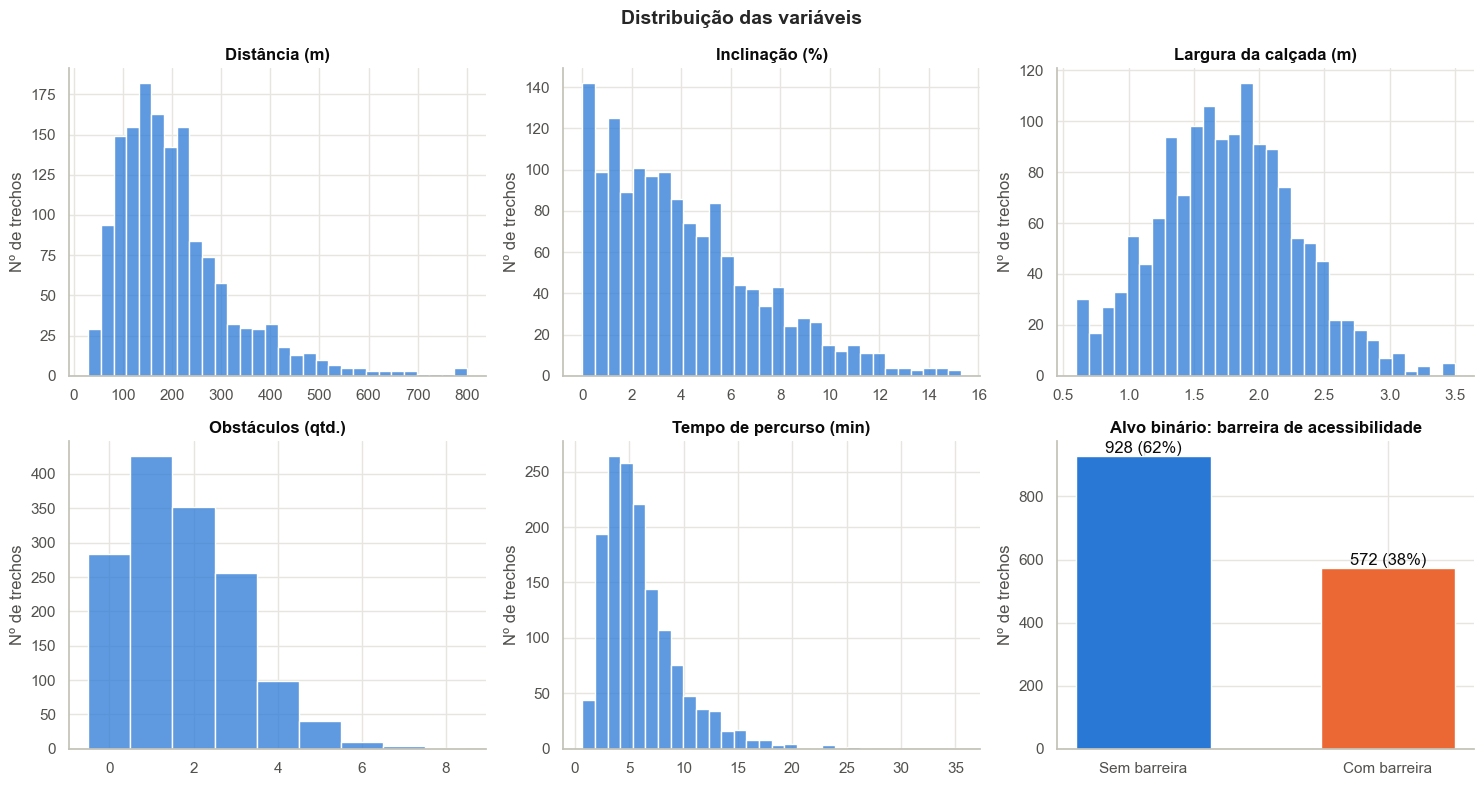

In [6]:
# Cópia apenas para visualização (o tratamento oficial vem na Seção 4)
viz = df_raw.drop_duplicates().copy()
viz["condicao_pavimento"] = viz["condicao_pavimento"].str.strip().str.lower()
viz.loc[viz["largura_calcada_m"] <= 0, "largura_calcada_m"] = np.nan
viz.loc[viz["inclinacao_pct"] > 30, "inclinacao_pct"] = np.nan

num_cols = ["distancia_m", "inclinacao_pct", "largura_calcada_m", "qtd_obstaculos", "tempo_percurso_min"]
rotulos = {"distancia_m": "Distância (m)", "inclinacao_pct": "Inclinação (%)",
           "largura_calcada_m": "Largura da calçada (m)", "qtd_obstaculos": "Obstáculos (qtd.)",
           "tempo_percurso_min": "Tempo de percurso (min)"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(viz[col].dropna(), ax=ax, color=AZUL, edgecolor="white", linewidth=1,
                 bins=30 if col != "qtd_obstaculos" else 9, discrete=(col == "qtd_obstaculos"))
    ax.set_title(rotulos[col]); ax.set_xlabel(""); ax.set_ylabel("Nº de trechos")
ax = axes.flat[5]
cont = viz["barreira_acessibilidade"].map({0: "Sem barreira", 1: "Com barreira"}).value_counts()
ax.bar(cont.index, cont.values, color=[AZUL, LARANJA], width=0.55)
for i, v in enumerate(cont.values):
    ax.text(i, v + 10, f"{v} ({v/cont.sum():.0%})", ha="center", color=TINTA)
ax.set_title("Alvo binário: barreira de acessibilidade"); ax.set_ylabel("Nº de trechos")
fig.suptitle("Distribuição das variáveis", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

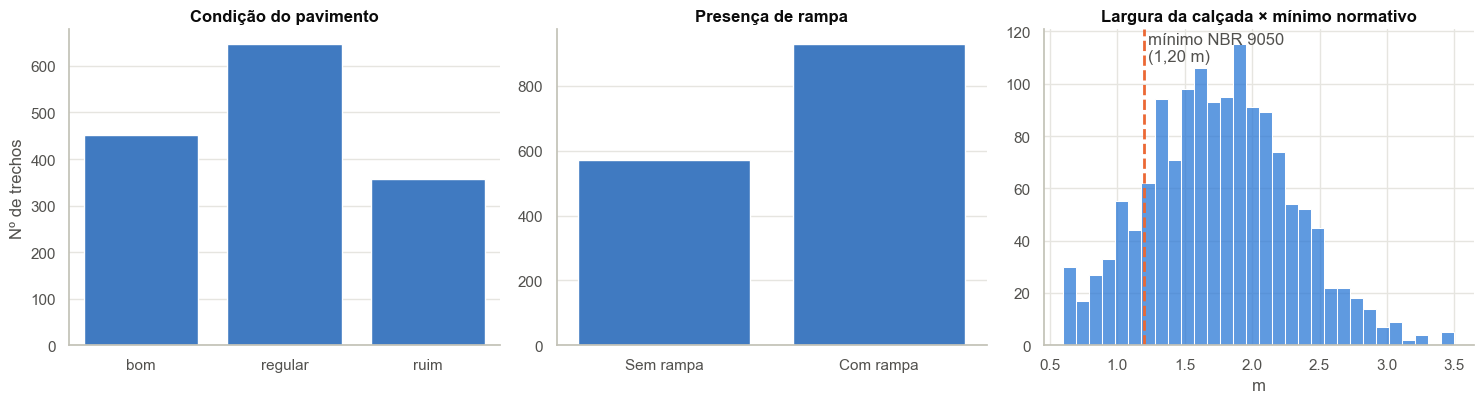

Trechos com calçada abaixo de 1,20 m: 14.8%
Trechos com inclinação acima de 8,33%: 10.4%


In [7]:
# Variáveis categóricas/binárias e linhas de referência da NBR 9050
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ordem_pav = ["bom", "regular", "ruim"]
sns.countplot(data=viz, x="condicao_pavimento", order=ordem_pav, color=AZUL, ax=axes[0])
axes[0].set_title("Condição do pavimento"); axes[0].set_xlabel(""); axes[0].set_ylabel("Nº de trechos")
sns.countplot(data=viz, x="presenca_rampa", color=AZUL, ax=axes[1])
axes[1].set_xticks([0, 1], ["Sem rampa", "Com rampa"]); axes[1].set_title("Presença de rampa")
axes[1].set_xlabel(""); axes[1].set_ylabel("")
sns.histplot(viz["largura_calcada_m"].dropna(), bins=30, color=AZUL, edgecolor="white", ax=axes[2])
axes[2].axvline(1.20, color=LARANJA, lw=2, ls="--"); axes[2].text(1.23, axes[2].get_ylim()[1]*0.9, "mínimo NBR 9050\n(1,20 m)", color=TINTA2)
axes[2].set_title("Largura da calçada × mínimo normativo"); axes[2].set_xlabel("m"); axes[2].set_ylabel("")
plt.tight_layout(); plt.show()

print(f"Trechos com calçada abaixo de 1,20 m: {(viz['largura_calcada_m'] < 1.2).mean():.1%}")
print(f"Trechos com inclinação acima de 8,33%: {(viz['inclinacao_pct'] > 8.33).mean():.1%}")

### 3.3 Relações com o alvo numérico (tempo de percurso)

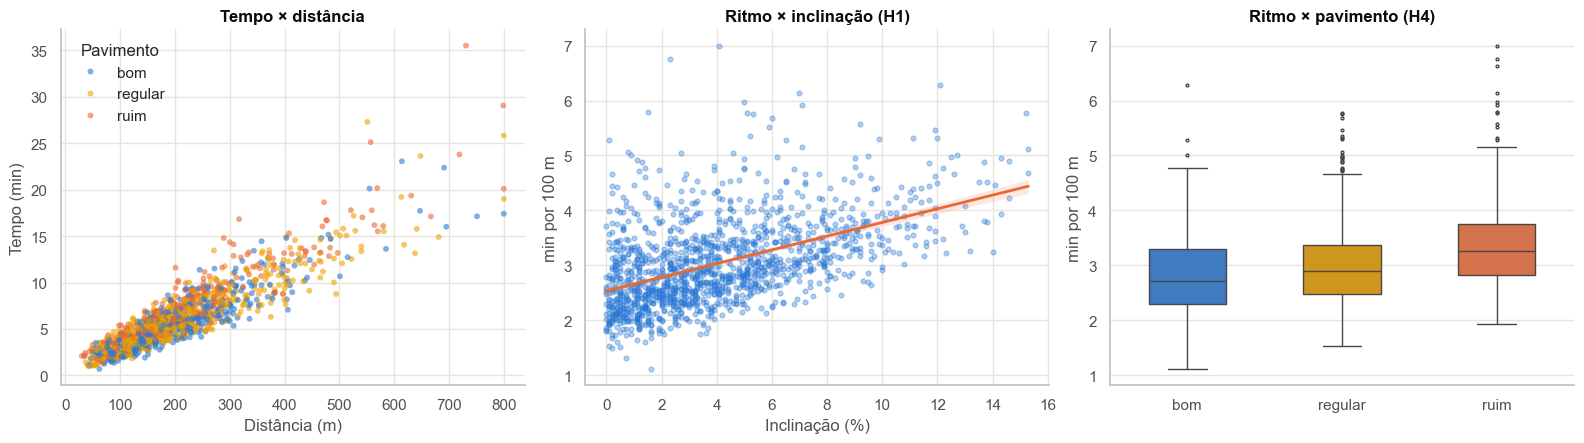

In [8]:
viz["ritmo_min_por_100m"] = viz["tempo_percurso_min"] / viz["distancia_m"] * 100   # tempo normalizado pela distância

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
cores_pav = {"bom": AZUL, "regular": AMARELO, "ruim": LARANJA}
sns.scatterplot(data=viz, x="distancia_m", y="tempo_percurso_min", hue="condicao_pavimento",
                hue_order=ordem_pav, palette=cores_pav, s=18, alpha=0.6, ax=axes[0], edgecolor="none")
axes[0].set_title("Tempo × distância"); axes[0].set_xlabel("Distância (m)"); axes[0].set_ylabel("Tempo (min)")
axes[0].legend(title="Pavimento", frameon=False)

sns.regplot(data=viz, x="inclinacao_pct", y="ritmo_min_por_100m", ax=axes[1], color=AZUL,
            scatter_kws={"s": 12, "alpha": 0.35}, line_kws={"color": LARANJA, "lw": 2})
axes[1].set_title("Ritmo × inclinação (H1)"); axes[1].set_xlabel("Inclinação (%)"); axes[1].set_ylabel("min por 100 m")

sns.boxplot(data=viz, x="condicao_pavimento", y="ritmo_min_por_100m", order=ordem_pav,
            palette=cores_pav, ax=axes[2], width=0.5, fliersize=2)
axes[2].set_title("Ritmo × pavimento (H4)"); axes[2].set_xlabel(""); axes[2].set_ylabel("min por 100 m")
plt.tight_layout(); plt.show()

### 3.4 Relações com o alvo binário (barreira de acessibilidade)

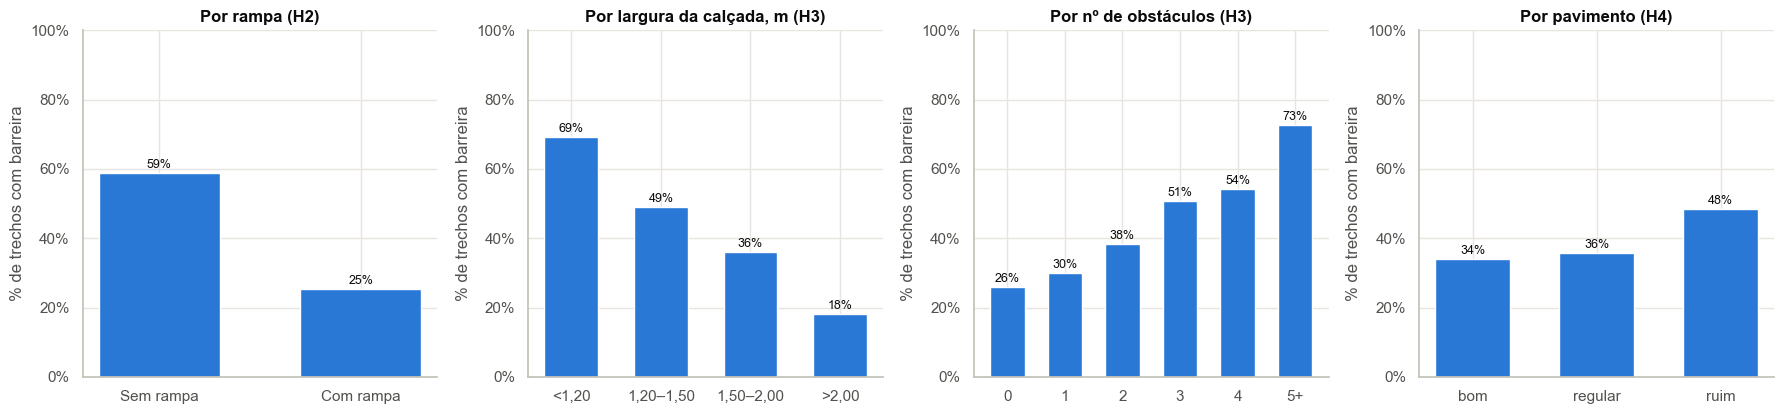

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))

def taxa_barreira(ax, serie, titulo, ordem=None):
    t = viz.groupby(serie, observed=True)["barreira_acessibilidade"].mean()
    if ordem is not None:
        t = t.reindex(ordem)
    ax.bar([str(i) for i in t.index], t.values, color=AZUL, width=0.6)
    for i, v in enumerate(t.values):
        ax.text(i, v + 0.015, f"{v:.0%}", ha="center", color=TINTA, fontsize=9)
    ax.set_ylim(0, 1); ax.set_title(titulo); ax.set_ylabel("% de trechos com barreira"); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))

taxa_barreira(axes[0], viz["presenca_rampa"].map({0: "Sem rampa", 1: "Com rampa"}), "Por rampa (H2)", ["Sem rampa", "Com rampa"])
faixa_larg = pd.cut(viz["largura_calcada_m"], [0, 1.2, 1.5, 2.0, 4], labels=["<1,20", "1,20–1,50", "1,50–2,00", ">2,00"])
taxa_barreira(axes[1], faixa_larg, "Por largura da calçada, m (H3)")
taxa_barreira(axes[2], viz["qtd_obstaculos"].clip(upper=5).map(lambda v: "5+" if v >= 5 else str(int(v)) if pd.notna(v) else np.nan),
              "Por nº de obstáculos (H3)", ["0", "1", "2", "3", "4", "5+"])
taxa_barreira(axes[3], viz["condicao_pavimento"], "Por pavimento (H4)", ordem_pav)
plt.tight_layout(); plt.show()

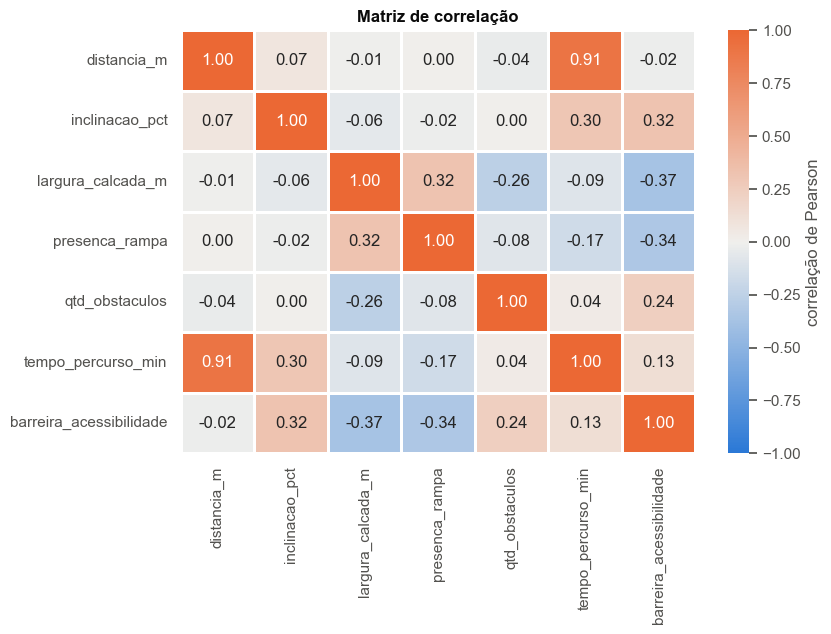

In [10]:
# Correlação entre variáveis numéricas (rampa e alvos incluídos para inspeção)
corr = viz[["distancia_m", "inclinacao_pct", "largura_calcada_m", "presenca_rampa", "qtd_obstaculos",
            "tempo_percurso_min", "barreira_acessibilidade"]].corr()
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=CMAP_DIV, vmin=-1, vmax=1, linewidths=2, linecolor="white",
            cbar_kws={"label": "correlação de Pearson"})
plt.title("Matriz de correlação"); plt.tight_layout(); plt.show()

**Principais achados da análise exploratória:**
- **Tempo × distância:** a distância é, de longe, o que mais explica o tempo (correlação **0,91**). Mesmo assim, para a mesma distância, a dispersão aumenta nos trechos longos, e os trechos com pavimento ruim ficam acima.
- **Ritmo × inclinação (H1):** o tempo por 100 m sobe de **2,5 min** (inclinação ≤ 2%) para **3,7 min** (acima de 8,33%), com mediana crescente em cada faixa.
- **Ritmo × pavimento (H4):** a mediana vai de **2,7 min/100 m** (bom) para **3,3 min/100 m** (ruim).
- **Barreira × rampa (H2):** **59%** dos trechos sem rampa têm barreira, contra **25%** dos trechos com rampa.
- **Barreira × largura (H3):** **69%** das calçadas abaixo de 1,20 m (o mínimo da NBR 9050) têm barreira, contra **18%** das calçadas acima de 2 m.
- **Barreira × obstáculos (H3):** a taxa cresce de **26%** (nenhum obstáculo) para **73%** (5 ou mais).
- **Correlação entre as entradas:** largura e rampa estão correlacionadas (**0,32**), assim como largura e obstáculos (**−0,26**): calçadas largas costumam ter rampa e menos obstáculos. Por isso o efeito de cada variável deve ser lido no modelo multivariado ("mantidas as demais constantes"), e não só nos gráficos de uma variável por vez.
- Os padrões da base são coerentes com as hipóteses. Como a base é simulada, isso é esperado por construção (ver Seção 10).

## 4. Limpeza, tratamento e preparação dos dados

A limpeza é dividida em duas partes, para **não haver vazamento de dados**:

| Etapa | Onde é feita | Por quê |
|---|---|---|
| Remover duplicatas, padronizar grafia, transformar valores impossíveis em ausentes, remover linhas sem o alvo | **Antes** da divisão treino/teste | São regras fixas, aplicadas linha a linha, que **não usam nenhuma estatística da base** (média, mediana etc.). Não há informação do teste "vazando" para o treino. |
| Preencher ausentes (mediana/moda), padronizar escalas, codificar categorias | **Depois** da divisão, dentro de um `Pipeline` | Essas etapas **aprendem** valores com os dados (ex.: a mediana). Elas são ajustadas **somente no treino** e apenas aplicadas no teste. |

In [11]:
df = df_raw.copy()
log = []                                                    # registro de cada passo da limpeza
log.append(("Base original", len(df)))

# 1) Duplicatas exatas (mesmo trecho cadastrado duas vezes)
df = df.drop_duplicates().reset_index(drop=True)
log.append(("Após remover duplicatas", len(df)))

# 2) Padronização da categoria (espaços e maiúsculas/minúsculas)
df["condicao_pavimento"] = df["condicao_pavimento"].str.strip().str.lower()
assert set(df["condicao_pavimento"].dropna().unique()) <= {"bom", "regular", "ruim"}

# 3) Valores impossíveis -> ausentes (serão imputados no Pipeline, com estatística do treino)
imp_larg = df["largura_calcada_m"] <= 0
imp_incl = df["inclinacao_pct"] > 30
df.loc[imp_larg, "largura_calcada_m"] = np.nan
df.loc[imp_incl, "inclinacao_pct"] = np.nan
print(f"Larguras impossíveis convertidas em ausentes: {imp_larg.sum()}")
print(f"Inclinações implausíveis convertidas em ausentes: {imp_incl.sum()}")

# 4) Linhas sem o alvo numérico: não servem para treinar nem para avaliar -> removidas
sem_alvo = df["tempo_percurso_min"].isna()
df = df.loc[~sem_alvo].reset_index(drop=True)
log.append(("Após remover linhas sem o alvo 'tempo'", len(df)))

# 5) Tipos corretos
df["presenca_rampa"] = df["presenca_rampa"].astype(int)
df["barreira_acessibilidade"] = df["barreira_acessibilidade"].astype(int)

print()
print(pd.DataFrame(log, columns=["Etapa", "Linhas"]).to_string(index=False))
print("\nAusentes restantes (serão imputados dentro do Pipeline):")
print(df.isna().sum()[df.isna().sum() > 0])

Larguras impossíveis convertidas em ausentes: 7
Inclinações implausíveis convertidas em ausentes: 6

                                 Etapa  Linhas
                         Base original    1515
               Após remover duplicatas    1500
Após remover linhas sem o alvo 'tempo'    1491

Ausentes restantes (serão imputados dentro do Pipeline):
inclinacao_pct        51
largura_calcada_m     51
qtd_obstaculos        30
condicao_pavimento    45
dtype: int64


In [12]:
# Outliers do alvo numérico: verificamos se são plausíveis (trechos longos/íngremes) antes de decidir
q1, q3 = df["tempo_percurso_min"].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
out = df[df["tempo_percurso_min"] > lim_sup]
print(f"Tempos acima do limite do boxplot ({lim_sup:.1f} min): {len(out)} trechos")
print(out[["distancia_m", "inclinacao_pct", "qtd_obstaculos", "condicao_pavimento", "tempo_percurso_min"]]
      .describe().loc[["mean", "min", "max"]].round(1))

Tempos acima do limite do boxplot (13.6 min): 64 trechos
      distancia_m  inclinacao_pct  qtd_obstaculos  tempo_percurso_min
mean      543.000           6.400           1.700              17.300
min       289.000           0.000           0.000              13.600
max       800.000          15.300           5.000              35.500


**Resultado da limpeza:** de 1.515 linhas, foram removidas **15 duplicatas** e **9 linhas sem o alvo**, restando **1.491 trechos**. As 13 medições impossíveis viraram ausentes e, junto com os demais ausentes (cerca de 3% por coluna), serão preenchidas **dentro do Pipeline**, com a mediana e a moda calculadas **apenas no treino**.

Os **64 tempos "altos"** (acima de 13,6 min) **não foram removidos**: são trechos longos (média de 543 m, mínimo de 289 m), portanto valores plausíveis, e não erros. Removê-los faria o modelo errar justamente nos trechos longos, que são os que mais pesam numa rota.

## 5. Separação entre treino e teste (sem vazamento de dados)

- **Uma única divisão** 80% treino / 20% teste, usada pelos dois modelos (os mesmos trechos ficam no teste dos dois).
- **Estratificada** pelo alvo binário, para que treino e teste tenham a mesma proporção de trechos com barreira.
- O **teste fica "trancado"**: só é usado uma vez, no final, para medir as métricas. Escolhas de modelo e de limiar usam **validação cruzada dentro do treino**.
- Todo o pré-processamento fica dentro de um `Pipeline` do scikit-learn: ao chamar `fit`, ele aprende mediana, moda, média e desvio-padrão **apenas com o treino**.

In [13]:
FEATURES_NUM = ["distancia_m", "inclinacao_pct", "largura_calcada_m", "qtd_obstaculos"]
FEATURES_BIN = ["presenca_rampa"]
FEATURES_CAT = ["condicao_pavimento"]
FEATURES = FEATURES_NUM + FEATURES_BIN + FEATURES_CAT

X = df[FEATURES]
y_tempo = df["tempo_percurso_min"]
y_barreira = df["barreira_acessibilidade"]

X_train, X_test, yt_train, yt_test, yb_train, yb_test = train_test_split(
    X, y_tempo, y_barreira, test_size=0.20, random_state=SEED, stratify=y_barreira)

print(f"Treino: {len(X_train)} trechos | Teste: {len(X_test)} trechos")
print(f"% com barreira -> treino {yb_train.mean():.1%} | teste {yb_test.mean():.1%}")
print(f"Tempo médio    -> treino {yt_train.mean():.2f} min | teste {yt_test.mean():.2f} min")
assert set(X_train.index).isdisjoint(X_test.index), "Treino e teste não podem compartilhar trechos!"

Treino: 1192 trechos | Teste: 299 trechos
% com barreira -> treino 38.0% | teste 38.1%
Tempo médio    -> treino 6.14 min | teste 5.97 min


In [14]:
def criar_preprocessador():
    # Pré-processamento aprendido SOMENTE no treino (dentro do Pipeline)
    numerico = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),   # mediana do TREINO
        ("padronizar", StandardScaler()),                # média/desvio do TREINO
    ])
    categorico = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("codificar", OneHotEncoder(categories=[["bom", "regular", "ruim"]], drop="first",
                                    handle_unknown="ignore")),   # 'bom' é a referência
    ])
    return ColumnTransformer([
        ("num", numerico, FEATURES_NUM),
        ("bin", "passthrough", FEATURES_BIN),
        ("cat", categorico, FEATURES_CAT),
    ])

NOMES_FEATURES = FEATURES_NUM + FEATURES_BIN + ["pavimento_regular", "pavimento_ruim"]
print("Variáveis que entram nos modelos após o pré-processamento:", NOMES_FEATURES)

Variáveis que entram nos modelos após o pré-processamento: ['distancia_m', 'inclinacao_pct', 'largura_calcada_m', 'qtd_obstaculos', 'presenca_rampa', 'pavimento_regular', 'pavimento_ruim']


## 6. Modelo 1 — Regressão Linear: tempo de percurso

**Pergunta P1:** quanto tempo um cadeirante leva para percorrer o trecho?

Métricas (calculadas no conjunto de **teste**):
- **MAE** (erro absoluto médio): em média, quantos minutos a previsão erra. Fácil de explicar ao usuário.
- **RMSE** (raiz do erro quadrático médio): também em minutos, mas penaliza mais os erros grandes.
- **R²**: fração da variação do tempo explicada pelo modelo (1 = perfeito; 0 = igual a chutar a média).

Para saber se o modelo é útil, comparamos com duas **linhas de base**: (1) prever sempre o tempo médio do treino; (2) uma regressão que usa **somente a distância**, que é o que um aplicativo de mapas comum faz (tempo = distância ÷ velocidade). A segunda é a referência mais exigente: mostra quanto as características de acessibilidade acrescentam além da distância.

In [15]:
def metricas_regressao(y_real, y_prev):
    return {"MAE (min)": mean_absolute_error(y_real, y_prev),
            "RMSE (min)": np.sqrt(mean_squared_error(y_real, y_prev)),
            "R²": r2_score(y_real, y_prev)}

modelo_lin = Pipeline([("prep", criar_preprocessador()), ("reg", LinearRegression())])
base_lin = Pipeline([("prep", criar_preprocessador()), ("reg", DummyRegressor(strategy="mean"))])

# Validação cruzada (5 dobras) somente no TREINO -> estimativa de estabilidade
cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_lin = cross_validate(modelo_lin, X_train, yt_train, cv=cv_reg,
                        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
print("Validação cruzada no treino (média ± desvio das 5 dobras):")
print(f"  MAE  = {-cv_lin['test_neg_mean_absolute_error'].mean():.3f} ± {cv_lin['test_neg_mean_absolute_error'].std():.3f} min")
print(f"  RMSE = {-cv_lin['test_neg_root_mean_squared_error'].mean():.3f} ± {cv_lin['test_neg_root_mean_squared_error'].std():.3f} min")
print(f"  R²   = {cv_lin['test_r2'].mean():.3f} ± {cv_lin['test_r2'].std():.3f}")

# Treino final e avaliação no TESTE
modelo_lin.fit(X_train, yt_train)
base_lin.fit(X_train, yt_train)
prev_tempo_train = modelo_lin.predict(X_train)
prev_tempo = modelo_lin.predict(X_test)

# Linha de base 2: regressão linear só com a distância (o "mapa comum"); distância não tem ausentes
base_dist = LinearRegression().fit(X_train[["distancia_m"]], yt_train)
prev_tempo_dist = base_dist.predict(X_test[["distancia_m"]])

tab_lin = pd.DataFrame({
    "Linha de base (média) — teste": metricas_regressao(yt_test, base_lin.predict(X_test)),
    "Linha de base (somente distância) — teste": metricas_regressao(yt_test, prev_tempo_dist),
    "Regressão Linear — treino": metricas_regressao(yt_train, prev_tempo_train),
    "Regressão Linear — TESTE": metricas_regressao(yt_test, prev_tempo),
}).T
tab_lin

Validação cruzada no treino (média ± desvio das 5 dobras):
  MAE  = 0.667 ± 0.039 min
  RMSE = 0.953 ± 0.081 min
  R²   = 0.930 ± 0.011


,MAE (min),RMSE (min),R²
Linha de base (média) — teste,2.616,3.692,-0.002
Linha de base (somente distância) — teste,1.065,1.573,0.818
Regressão Linear — treino,0.657,0.939,0.934
Regressão Linear — TESTE,0.636,1.077,0.915


In [16]:
# Coeficientes em unidades originais (desfazendo a padronização) -> interpretação direta
reg = modelo_lin.named_steps["reg"]
escala = modelo_lin.named_steps["prep"].named_transformers_["num"].named_steps["padronizar"].scale_
coef_orig = np.concatenate([reg.coef_[:4] / escala, reg.coef_[4:]])
unidades = ["por metro", "por ponto % de inclinação", "por metro de largura", "por obstáculo",
            "com rampa (vs. sem)", "regular (vs. bom)", "ruim (vs. bom)"]
coef_lin = pd.DataFrame({"variável": NOMES_FEATURES, "efeito (min)": coef_orig, "unidade": unidades,
                         "coef. padronizado": reg.coef_})
print(f"Intercepto (modelo padronizado): {reg.intercept_:.3f} min")
coef_lin

Intercepto (modelo padronizado): 6.405 min


,variável,efeito (min),unidade,coef. padronizado
0,distancia_m,0.027,por metro,3.271
1,inclinacao_pct,0.273,por ponto % de inclinação,0.836
2,largura_calcada_m,-0.037,por metro de largura,-0.020
3,qtd_obstaculos,0.178,por obstáculo,0.241
4,presenca_rampa,-1.216,com rampa (vs. sem),-1.216
5,pavimento_regular,0.392,regular (vs. bom),0.392
6,pavimento_ruim,1.246,ruim (vs. bom),1.246


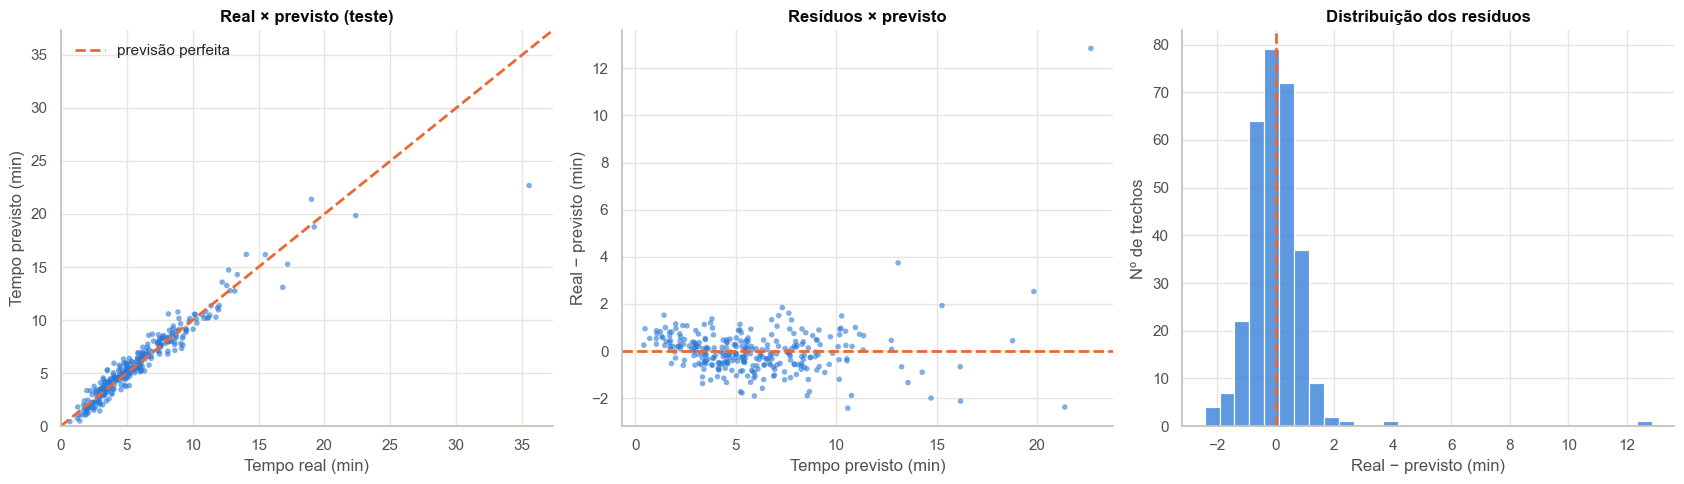

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
res = yt_test - prev_tempo

# (a) Real × previsto
ax = axes[0]
ax.scatter(yt_test, prev_tempo, s=16, alpha=0.6, color=AZUL, edgecolor="none")
lim = [0, max(yt_test.max(), prev_tempo.max()) * 1.05]
ax.plot(lim, lim, color=LARANJA, lw=2, ls="--", label="previsão perfeita")
ax.set_xlim(lim); ax.set_ylim(lim); ax.legend(frameon=False)
ax.set_title("Real × previsto (teste)"); ax.set_xlabel("Tempo real (min)"); ax.set_ylabel("Tempo previsto (min)")

# (b) Resíduos × previsto
ax = axes[1]
ax.scatter(prev_tempo, res, s=16, alpha=0.6, color=AZUL, edgecolor="none")
ax.axhline(0, color=LARANJA, lw=2, ls="--")
ax.set_title("Resíduos × previsto"); ax.set_xlabel("Tempo previsto (min)"); ax.set_ylabel("Real − previsto (min)")

# (c) Distribuição dos resíduos
ax = axes[2]
sns.histplot(res, bins=30, color=AZUL, edgecolor="white", ax=ax)
ax.axvline(0, color=LARANJA, lw=2, ls="--")
ax.set_title("Distribuição dos resíduos"); ax.set_xlabel("Real − previsto (min)"); ax.set_ylabel("Nº de trechos")
plt.tight_layout(); plt.show()

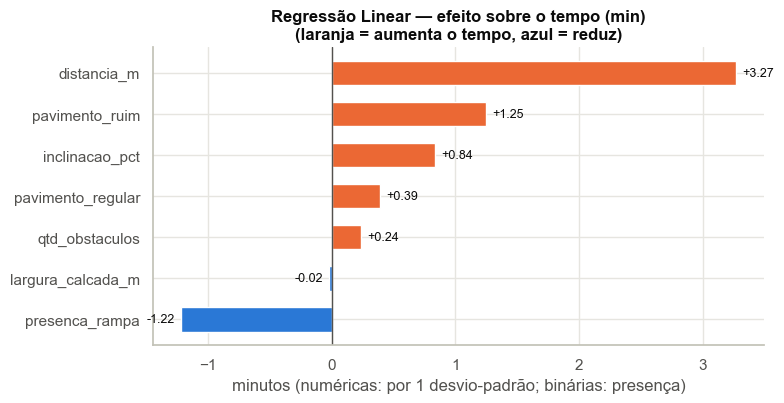

In [18]:
# Importância relativa: coeficientes padronizados (efeito de +1 desvio-padrão; binárias: 0 -> 1)
c = coef_lin.set_index("variável")["coef. padronizado"].sort_values()
plt.figure(figsize=(8, 4.2))
plt.barh(c.index, c.values, color=[LARANJA if v > 0 else AZUL for v in c.values], height=0.6)
plt.axvline(0, color=TINTA2, lw=1)
for i, v in enumerate(c.values):
    plt.text(v + (0.05 if v >= 0 else -0.05), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", color=TINTA, fontsize=9)
plt.title("Regressão Linear — efeito sobre o tempo (min)\n(laranja = aumenta o tempo, azul = reduz)")
plt.xlabel("minutos (numéricas: por 1 desvio-padrão; binárias: presença)")
plt.tight_layout(); plt.show()

In [19]:
# Onde o modelo erra mais? Erro absoluto por faixa de distância
seg = pd.DataFrame({"distancia": X_test["distancia_m"], "erro_abs": res.abs(), "real": yt_test})
seg["faixa"] = pd.cut(seg["distancia"], [0, 100, 200, 300, 800], labels=["até 100 m", "100–200 m", "200–300 m", "> 300 m"])
erro_faixa = seg.groupby("faixa", observed=True).agg(trechos=("erro_abs", "size"), MAE_min=("erro_abs", "mean"),
                                                     tempo_medio_real=("real", "mean"))
erro_faixa["erro_relativo"] = erro_faixa["MAE_min"] / erro_faixa["tempo_medio_real"]
erro_faixa

,trechos,MAE_min,tempo_medio_real,erro_relativo
faixa,,,,
até 100 m,46,0.578,2.488,0.232
100–200 m,130,0.510,4.490,0.114
200–300 m,82,0.556,7.217,0.077
> 300 m,41,1.259,12.109,0.104


### 6.1 Variação: regressão linear com termos de interação
Os gráficos de resíduos indicam (ver interpretação abaixo) que os efeitos de inclinação, obstáculos e pavimento **crescem com a distância** — fisicamente faz sentido: uma subida de 8% custa mais tempo num trecho de 400 m do que num de 50 m. Uma regressão linear simples soma efeitos fixos e não captura isso. Testamos então a **mesma regressão linear**, acrescentando termos de interação entre pares de variáveis (`PolynomialFeatures(interaction_only=True)`), também avaliada com validação cruzada no treino e só depois no teste.

In [20]:
modelo_lin_int = Pipeline([
    ("prep", criar_preprocessador()),
    ("interacoes", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
    ("reg", LinearRegression()),
])
cv_int = cross_validate(modelo_lin_int, X_train, yt_train, cv=cv_reg,
                        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"])
modelo_lin_int.fit(X_train, yt_train)
prev_tempo_int = modelo_lin_int.predict(X_test)

comp_lin = pd.DataFrame({
    "Linear simples — CV treino": {"MAE (min)": -cv_lin["test_neg_mean_absolute_error"].mean(),
                                   "RMSE (min)": -cv_lin["test_neg_root_mean_squared_error"].mean(),
                                   "R²": cv_lin["test_r2"].mean()},
    "Linear c/ interações — CV treino": {"MAE (min)": -cv_int["test_neg_mean_absolute_error"].mean(),
                                         "RMSE (min)": -cv_int["test_neg_root_mean_squared_error"].mean(),
                                         "R²": cv_int["test_r2"].mean()},
    "Linear simples — TESTE": metricas_regressao(yt_test, prev_tempo),
    "Linear c/ interações — TESTE": metricas_regressao(yt_test, prev_tempo_int),
}).T
print(f"Nº de variáveis: simples = {len(NOMES_FEATURES)} | com interações = "
      f"{modelo_lin_int.named_steps['interacoes'].n_output_features_}")
comp_lin

Nº de variáveis: simples = 7 | com interações = 28


,MAE (min),RMSE (min),R²
Linear simples — CV treino,0.667,0.953,0.930
Linear c/ interações — CV treino,0.528,0.742,0.958
Linear simples — TESTE,0.636,1.077,0.915
Linear c/ interações — TESTE,0.483,0.729,0.961


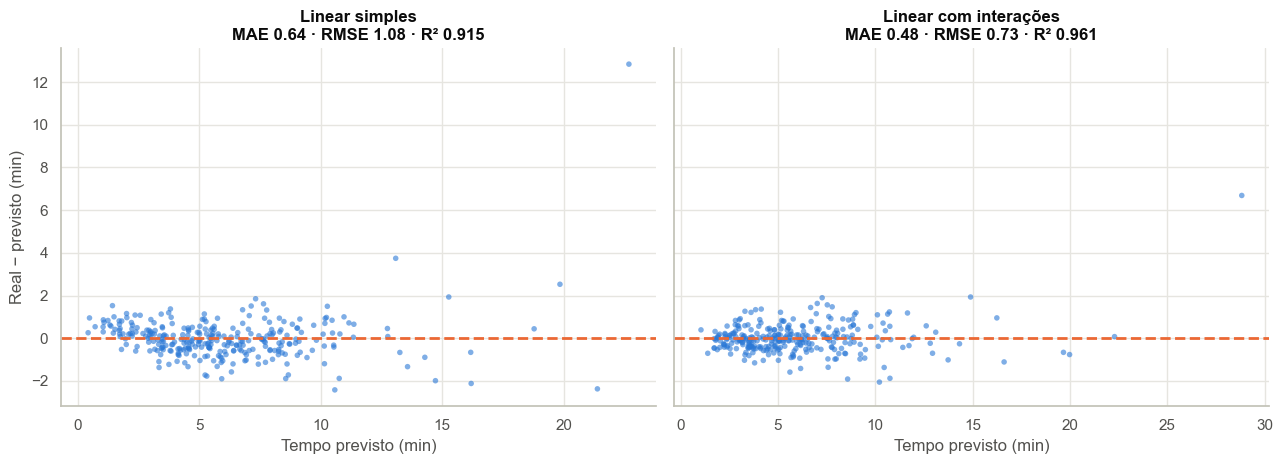

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, prev, titulo in [(axes[0], prev_tempo, "Linear simples"), (axes[1], prev_tempo_int, "Linear com interações")]:
    ax.scatter(prev, yt_test - prev, s=16, alpha=0.6, color=AZUL, edgecolor="none")
    ax.axhline(0, color=LARANJA, lw=2, ls="--")
    m = metricas_regressao(yt_test, prev)
    ax.set_title(f"{titulo}\nMAE {m['MAE (min)']:.2f} · RMSE {m['RMSE (min)']:.2f} · R² {m['R²']:.3f}")
    ax.set_xlabel("Tempo previsto (min)")
axes[0].set_ylabel("Real − previsto (min)")
plt.tight_layout(); plt.show()

### Interpretação — Regressão Linear

**Desempenho (teste, 299 trechos nunca vistos):**
| Métrica | Linha de base (média) | Linha de base (somente distância) | Regressão Linear | Leitura |
|---|---|---|---|---|
| **MAE** | 2,62 min | 1,07 min | **0,64 min** | em média, a previsão erra cerca de 38 segundos por trecho: **40% menos** que usar só a distância (como um mapa comum) e 4 vezes menos que chutar a média |
| **R²** | 0,00 | 0,818 | **0,915** | as características de acessibilidade explicam boa parte da variação que a distância sozinha não explica |
| **RMSE** | 3,69 min | 1,57 min | **1,08 min** | maior que o MAE porque o RMSE pesa mais os erros grandes. Um único trecho do teste (tempo real de 35,5 min, previsto 22,7 min) responde por boa parte da diferença em relação à validação cruzada (0,95 min) |

- **Sem sobreajuste:** os resultados no treino (MAE 0,66, R² 0,934), na validação cruzada (MAE 0,667 ± 0,039, R² 0,930 ± 0,011) e no teste são próximos. O modelo generaliza.
- **O que cada variável faz** (coeficientes em unidades originais, mantidas as demais constantes): cada metro acrescenta **0,027 min** (cerca de 2,7 min a cada 100 m); cada ponto percentual de inclinação acrescenta **0,27 min**; cada obstáculo, **0,18 min**; ter rampa **reduz 1,2 min** (evita o desvio); pavimento ruim acrescenta **1,25 min** em relação ao bom. A largura praticamente não tem efeito linear (−0,04 min/m): no gerador, a largura só pesa no tempo **abaixo de 1,20 m**, e uma reta não captura esse "degrau".
- **Onde o modelo erra:** o gráfico de resíduos tem formato de **funil**, com erros que crescem com o tempo previsto. Nos trechos com mais de 300 m, o MAE é de **1,26 min**, o dobro das outras faixas. Em termos relativos, porém, o maior erro está nos trechos curtos (≈ 23% do tempo nos trechos de até 100 m).
- **Por que isso acontece:** no mundo físico, a inclinação e os obstáculos **multiplicam** o esforço ao longo do trecho, enquanto a regressão linear simples apenas **soma** efeitos fixos.
- **Melhoria testada (6.1):** a mesma regressão linear com **termos de interação** reduziu o erro no teste para **MAE 0,48 min, RMSE 0,73 min e R² 0,961**, confirmado pela validação cruzada no treino (MAE 0,528, R² 0,958). Para a **interpretação** (hipóteses, explicação ao usuário) usamos o modelo simples, que tem 7 coeficientes legíveis. Para o **cálculo de tempo no app**, a versão com interações é a recomendada.

## 7. Modelo 2 — Regressão Logística: barreira de acessibilidade

**Pergunta P2:** qual a probabilidade de um trecho ter barreira de acessibilidade?

A regressão logística devolve uma **probabilidade** entre 0 e 1. Para virar decisão ("evitar" ou "não evitar" o trecho) é preciso um **limiar**. Começamos pelo limiar padrão de 0,5 e depois discutimos qual limiar faz mais sentido para o RotaApta.

Métricas (no **teste**), considerando "com barreira" como classe positiva:
- **Matriz de confusão:** acertos e erros de cada tipo.
- **Precisão:** dos trechos que o modelo marcou como "com barreira", quantos realmente têm.
- **Recall (sensibilidade):** dos trechos que realmente têm barreira, quantos o modelo encontrou. **Para o cadeirante, este é o erro mais grave**: um trecho com barreira classificado como livre pode deixá-lo preso no meio do caminho.
- **F1-score:** média harmônica entre precisão e recall.

Linhas de base: (1) sempre prever a classe mais comum ("sem barreira"); (2) a **regra simples "sem rampa = barreira"**, que é o que alguém faria sem modelo. O modelo só vale a pena se superar a regra simples.

**Configuração do modelo:** usamos a `LogisticRegression` do scikit-learn com seu padrão, a **penalização L2 com C = 1**. Ela encolhe levemente os coeficientes para reduzir o sobreajuste, então as razões de chances ficam um pouco mais próximas de 1 do que numa regressão logística sem penalização. Conferimos à parte que, sem penalização, as probabilidades previstas mudam no máximo cerca de 0,01 nesta base, sem alterar as conclusões.

In [22]:
def metricas_classificacao(y_real, y_prev, prob=None):
    m = {"Acurácia": accuracy_score(y_real, y_prev),
         "Precisão": precision_score(y_real, y_prev, zero_division=0),
         "Recall": recall_score(y_real, y_prev),
         "F1-score": f1_score(y_real, y_prev)}
    if prob is not None:
        m["AUC-ROC"] = roc_auc_score(y_real, prob)
    return m

modelo_log = Pipeline([("prep", criar_preprocessador()),
                       ("clf", LogisticRegression(max_iter=1000))])
base_log = Pipeline([("prep", criar_preprocessador()), ("clf", DummyClassifier(strategy="most_frequent"))])

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_log = cross_validate(modelo_log, X_train, yb_train, cv=cv_clf,
                        scoring=["precision", "recall", "f1", "roc_auc"])
print("Validação cruzada no treino (limiar 0,5):")
for k in ["precision", "recall", "f1", "roc_auc"]:
    print(f"  {k:9s} = {cv_log['test_' + k].mean():.3f} ± {cv_log['test_' + k].std():.3f}")

modelo_log.fit(X_train, yb_train)
base_log.fit(X_train, yb_train)
prob_barreira = modelo_log.predict_proba(X_test)[:, 1]
pred_barreira_05 = (prob_barreira >= 0.5).astype(int)

regra_sem_rampa = (1 - X_test["presenca_rampa"]).astype(int)    # "sem rampa = barreira"
cm_regra = confusion_matrix(yb_test, regra_sem_rampa)

tab_log = pd.DataFrame({
    "Linha de base (classe mais comum) — teste": metricas_classificacao(yb_test, base_log.predict(X_test)),
    "Regra 'sem rampa = barreira' — teste": metricas_classificacao(yb_test, regra_sem_rampa),
    "Reg. Logística — treino": metricas_classificacao(yb_train, modelo_log.predict(X_train),
                                                      modelo_log.predict_proba(X_train)[:, 1]),
    "Reg. Logística — TESTE (limiar 0,5)": metricas_classificacao(yb_test, pred_barreira_05, prob_barreira),
}).T
print("Matriz da regra 'sem rampa' [VN, FP, FN, VP]:", cm_regra.ravel().tolist())
tab_log

Validação cruzada no treino (limiar 0,5):
  precision = 0.722 ± 0.051
  recall    = 0.631 ± 0.067
  f1        = 0.672 ± 0.052
  roc_auc   = 0.833 ± 0.035
Matriz da regra 'sem rampa' [VN, FP, FN, VP]: [138, 47, 59, 55]


,Acurácia,Precisão,Recall,F1-score,AUC-ROC
Linha de base (classe mais comum) — teste,0.619,0.000,0.000,0.000,NaN
Regra 'sem rampa = barreira' — teste,0.645,0.539,0.482,0.509,NaN
Reg. Logística — treino,0.770,0.725,0.636,0.678,0.837
"Reg. Logística — TESTE (limiar 0,5)",0.729,0.685,0.535,0.601,0.794


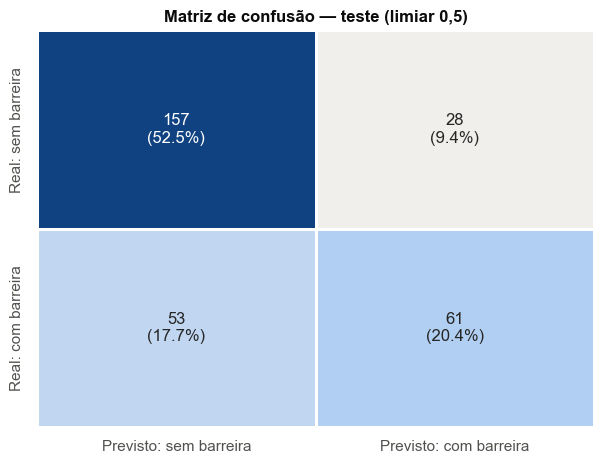

Verdadeiros negativos (livre e previsto livre): 157
Falsos positivos (livre, mas marcado com barreira -> desvio desnecessário): 28
Falsos negativos (barreira NÃO detectada -> risco para o cadeirante): 53
Verdadeiros positivos (barreira detectada): 61

              precision    recall  f1-score   support

sem barreira      0.748     0.849     0.795       185
com barreira      0.685     0.535     0.601       114

    accuracy                          0.729       299
   macro avg      0.717     0.692     0.698       299
weighted avg      0.724     0.729     0.721       299



In [23]:
def plot_matriz(ax, y_real, y_prev, titulo):
    cm = confusion_matrix(y_real, y_prev)
    tot = cm.sum()
    rot = np.array([[f"{v}\n({v/tot:.1%})" for v in linha] for linha in cm])
    sns.heatmap(cm, annot=rot, fmt="", cmap=CMAP_SEQ, cbar=False, linewidths=2, linecolor="white", ax=ax,
                annot_kws={"fontsize": 12},
                xticklabels=["Previsto: sem barreira", "Previsto: com barreira"],
                yticklabels=["Real: sem barreira", "Real: com barreira"])
    ax.set_title(titulo)
    return cm

fig, ax = plt.subplots(figsize=(6.2, 4.8))
cm05 = plot_matriz(ax, yb_test, pred_barreira_05, "Matriz de confusão — teste (limiar 0,5)")
plt.tight_layout(); plt.show()
vn, fp, fn, vp = cm05.ravel()
print(f"Verdadeiros negativos (livre e previsto livre): {vn}")
print(f"Falsos positivos (livre, mas marcado com barreira -> desvio desnecessário): {fp}")
print(f"Falsos negativos (barreira NÃO detectada -> risco para o cadeirante): {fn}")
print(f"Verdadeiros positivos (barreira detectada): {vp}\n")
print(classification_report(yb_test, pred_barreira_05, target_names=["sem barreira", "com barreira"], digits=3))

In [24]:
# Coeficientes -> razão de chances (odds ratio): quanto as chances de barreira se multiplicam
clf = modelo_log.named_steps["clf"]
escala_log = modelo_log.named_steps["prep"].named_transformers_["num"].named_steps["padronizar"].scale_
coef_log_orig = np.concatenate([clf.coef_[0][:4] / escala_log, clf.coef_[0][4:]])
unid_log = ["por +100 m", "por +1 ponto % de inclinação", "por +0,5 m de largura", "por +1 obstáculo",
            "com rampa (vs. sem)", "regular (vs. bom)", "ruim (vs. bom)"]
passo = np.array([100, 1, 0.5, 1, 1, 1, 1])
coef_log = pd.DataFrame({"variável": NOMES_FEATURES, "coef. padronizado": clf.coef_[0],
                         "razão de chances": np.exp(coef_log_orig * passo), "unidade": unid_log})
coef_log

,variável,coef. padronizado,razão de chances,unidade
0,distancia_m,-0.121,0.904,por +100 m
1,inclinacao_pct,0.876,1.331,por +1 ponto % de inclinação
2,largura_calcada_m,-0.738,0.499,"por +0,5 m de largura"
3,qtd_obstaculos,0.407,1.351,por +1 obstáculo
4,presenca_rampa,-1.408,0.245,com rampa (vs. sem)
5,pavimento_regular,0.230,1.259,regular (vs. bom)
6,pavimento_ruim,0.953,2.594,ruim (vs. bom)


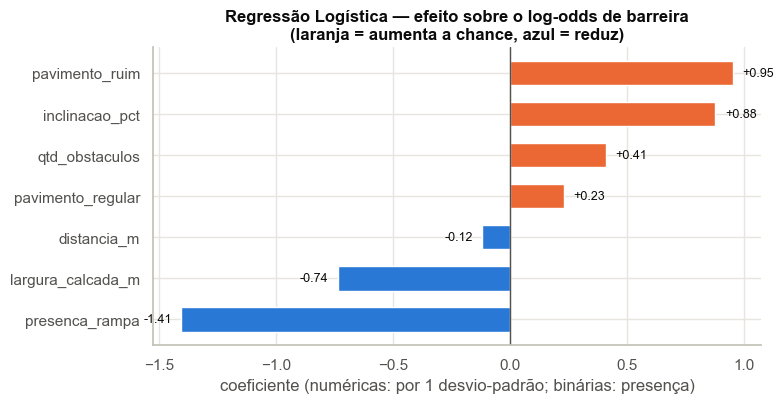

In [25]:
c = coef_log.set_index("variável")["coef. padronizado"].sort_values()
plt.figure(figsize=(8, 4.2))
plt.barh(c.index, c.values, color=[LARANJA if v > 0 else AZUL for v in c.values], height=0.6)
plt.axvline(0, color=TINTA2, lw=1)
for i, v in enumerate(c.values):
    plt.text(v + (0.04 if v >= 0 else -0.04), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", color=TINTA, fontsize=9)
plt.title("Regressão Logística — efeito sobre o log-odds de barreira\n(laranja = aumenta a chance, azul = reduz)")
plt.xlabel("coeficiente (numéricas: por 1 desvio-padrão; binárias: presença)")
plt.tight_layout(); plt.show()

### 7.1 Escolha do limiar de decisão (sem usar o teste)
Num app para cadeirantes, **deixar passar uma barreira (falso negativo) é pior do que sugerir um desvio desnecessário (falso positivo)**. Por isso definimos como critério: **entre os limiares que atingem recall de pelo menos 90% na validação cruzada do treino, escolher o de maior precisão**. Na prática, é o limiar mais alto que ainda mantém esse recall, o que evita falsos alertas desnecessários. Como o limiar é escolhido no treino, o recall no teste pode ficar um pouco diferente de 90% (aqui, 89,5%).

Para não "espiar" o teste, o limiar é escolhido com **probabilidades fora-da-dobra** (`cross_val_predict`) calculadas **só no treino**. Depois aplicamos esse limiar fixo ao teste.

In [26]:
RECALL_ALVO = 0.90
prob_oof = cross_val_predict(modelo_log, X_train, yb_train, cv=cv_clf, method="predict_proba")[:, 1]
prec_c, rec_c, lim_c = precision_recall_curve(yb_train, prob_oof)
# rec_c/prec_c têm um elemento a mais que lim_c; alinhamos pelo índice
validos = np.where(rec_c[:-1] >= RECALL_ALVO)[0]
idx = validos[np.argmax(prec_c[validos])]
LIMIAR = float(lim_c[idx])
print(f"Limiar escolhido no treino (recall >= {RECALL_ALVO:.0%}): {LIMIAR:.3f}")
print(f"  no treino (fora-da-dobra): precisão {prec_c[idx]:.3f} | recall {rec_c[idx]:.3f}")

pred_barreira = (prob_barreira >= LIMIAR).astype(int)
tab_limiar = pd.DataFrame({
    "TESTE — limiar 0,5": metricas_classificacao(yb_test, pred_barreira_05, prob_barreira),
    f"TESTE — limiar {LIMIAR:.2f} (recall-alvo)": metricas_classificacao(yb_test, pred_barreira, prob_barreira),
}).T
tab_limiar

Limiar escolhido no treino (recall >= 90%): 0.195
  no treino (fora-da-dobra): precisão 0.519 | recall 0.901


,Acurácia,Precisão,Recall,F1-score,AUC-ROC
"TESTE — limiar 0,5",0.729,0.685,0.535,0.601,0.794
TESTE — limiar 0.20 (recall-alvo),0.649,0.523,0.895,0.660,0.794


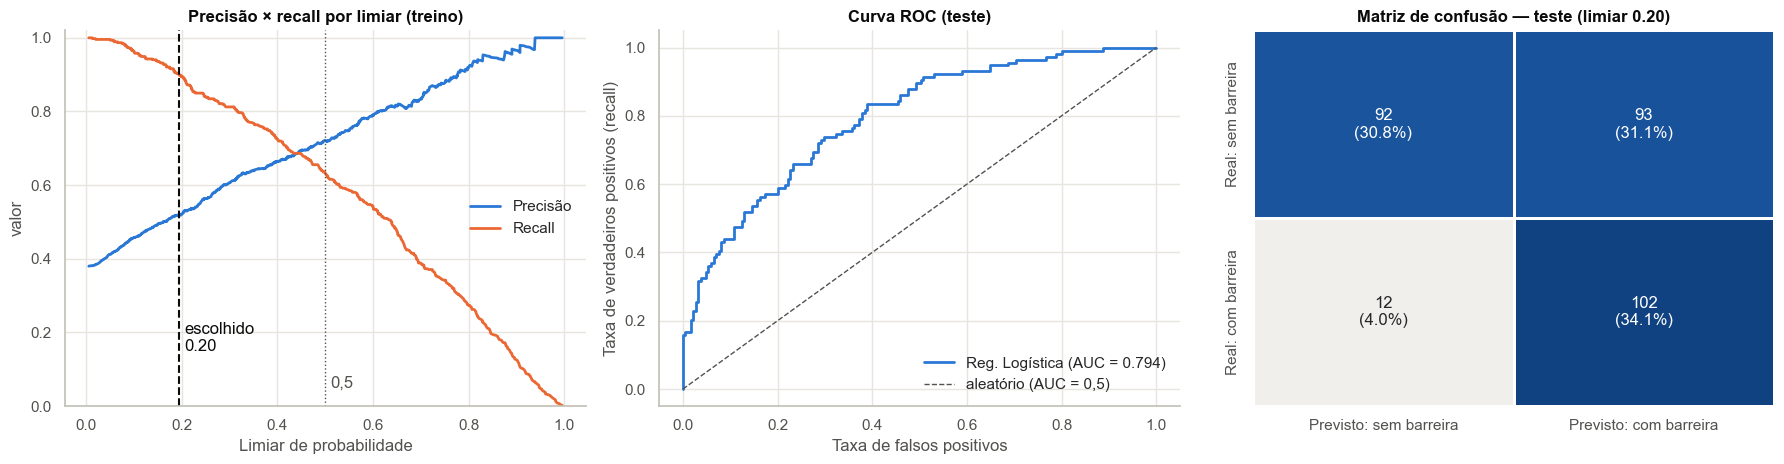

Com limiar 0.20: falsos negativos 53 -> 12 | falsos positivos 28 -> 93


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (a) Precisão e recall em função do limiar (treino, fora-da-dobra)
ax = axes[0]
ax.plot(lim_c, prec_c[:-1], color=AZUL, lw=2, label="Precisão")
ax.plot(lim_c, rec_c[:-1], color=LARANJA, lw=2, label="Recall")
ax.axvline(0.5, color=TINTA2, lw=1, ls=":"); ax.text(0.51, 0.05, "0,5", color=TINTA2)
ax.axvline(LIMIAR, color=TINTA, lw=1.5, ls="--"); ax.text(LIMIAR + 0.01, 0.15, f"escolhido\n{LIMIAR:.2f}", color=TINTA)
ax.set_xlabel("Limiar de probabilidade"); ax.set_ylabel("valor"); ax.set_ylim(0, 1.02)
ax.set_title("Precisão × recall por limiar (treino)"); ax.legend(frameon=False)

# (b) Curva ROC no teste
ax = axes[1]
fpr, tpr, _ = roc_curve(yb_test, prob_barreira)
ax.plot(fpr, tpr, color=AZUL, lw=2, label=f"Reg. Logística (AUC = {roc_auc_score(yb_test, prob_barreira):.3f})")
ax.plot([0, 1], [0, 1], color=TINTA2, lw=1, ls="--", label="aleatório (AUC = 0,5)")
ax.set_xlabel("Taxa de falsos positivos"); ax.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax.set_title("Curva ROC (teste)"); ax.legend(frameon=False, loc="lower right")

# (c) Matriz de confusão com o limiar escolhido
cm_lim = plot_matriz(axes[2], yb_test, pred_barreira, f"Matriz de confusão — teste (limiar {LIMIAR:.2f})")
plt.tight_layout(); plt.show()
vn2, fp2, fn2, vp2 = cm_lim.ravel()
print(f"Com limiar {LIMIAR:.2f}: falsos negativos {fn} -> {fn2} | falsos positivos {fp} -> {fp2}")

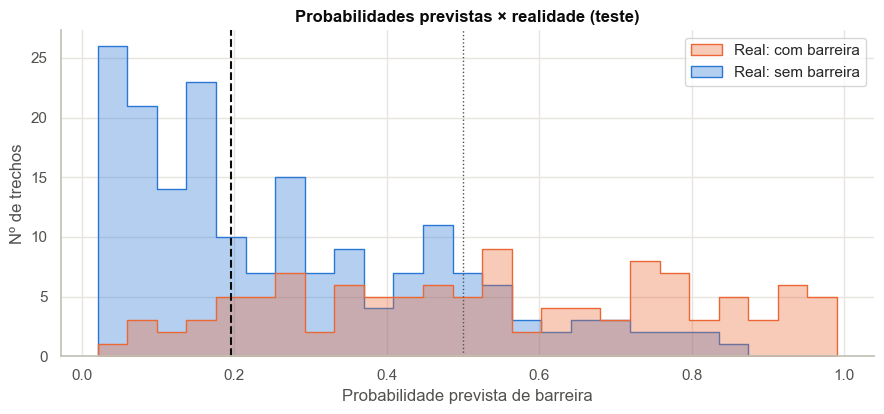

In [28]:
# Separação das probabilidades previstas por classe real (teste)
plt.figure(figsize=(9, 4.3))
sns.histplot(x=prob_barreira, hue=yb_test.map({0: "Real: sem barreira", 1: "Real: com barreira"}).values,
             bins=25, palette={"Real: sem barreira": AZUL, "Real: com barreira": LARANJA},
             element="step", stat="count", common_norm=False, alpha=0.35)
plt.axvline(0.5, color=TINTA2, ls=":", lw=1); plt.axvline(LIMIAR, color=TINTA, ls="--", lw=1.5)
plt.xlabel("Probabilidade prevista de barreira"); plt.ylabel("Nº de trechos")
plt.title("Probabilidades previstas × realidade (teste)")
plt.tight_layout(); plt.show()

### Interpretação — Regressão Logística

**Desempenho no teste (classe positiva = "com barreira"; 114 dos 299 trechos):**
| Métrica | Sempre "sem barreira" | Regra "sem rampa = barreira" | Logística, limiar 0,5 | Logística, limiar 0,20 (escolhido no treino) |
|---|---|---|---|---|
| Matriz [VN, FP, FN, VP] | [185, 0, 114, 0] | [138, 47, 59, 55] | [157, 28, 53, 61] | [92, 93, 12, 102] |
| **Precisão** | — | 0,539 | **0,685** | 0,523 |
| **Recall** | 0,000 | 0,482 | **0,535** | **0,895** |
| **F1-score** | 0,000 | 0,509 | **0,601** | **0,660** |
| AUC-ROC | — | — | 0,794 | 0,794 |

- **O modelo supera a regra simples:** no mesmo limiar de decisão, o F1 sobe de 0,509 para 0,601 (+0,09), com mais precisão e mais recall. A rampa sozinha não basta; largura, obstáculos, inclinação e pavimento acrescentam informação.

As métricas batem com a matriz de confusão. Com o limiar 0,5: precisão = 61 / (61 + 28) = 0,685; recall = 61 / (61 + 53) = 0,535; F1 = 2 × 0,685 × 0,535 / (0,685 + 0,535) = 0,601.

- **Com o limiar padrão (0,5),** o modelo acerta a maioria dos alertas (precisão de 69%), mas **deixa passar 53 das 114 barreiras** (recall de 54%). Para um cadeirante, isso significa quase metade das barreiras sem aviso, o que é inaceitável como regra do app.
- **Com o limiar escolhido no treino (0,20),** o recall sobe para **89,5%**: as barreiras não detectadas caem de **53 para 12**. O custo são mais falsos alarmes (de 28 para 93), ou seja, desvios às vezes desnecessários. O F1 também melhora (0,601 → 0,660). No RotaApta, um falso alarme custa alguns minutos; um falso negativo pode deixar a pessoa sem saída. Por isso adotamos o limiar de 0,20.
- **AUC de 0,79** (validação cruzada: 0,83 ± 0,04): o modelo ordena bem os trechos por risco, bem acima do acaso (0,5). Ainda assim, há sobreposição entre as classes, já que a barreira depende também de fatores que não estão na base.
- **Razões de chances (mantidas as demais variáveis):** ter rampa multiplica as chances de barreira por **0,25** (uma redução de cerca de 75%); cada +0,5 m de largura, por **0,50**; cada ponto % de inclinação, por **1,33**; cada obstáculo, por **1,35**; pavimento ruim, por **2,59** em relação ao bom. A distância tem efeito pequeno (0,90 a cada 100 m) e não faz parte das hipóteses.
- **Treino × teste:** os valores do treino (F1 0,678) e da validação cruzada (F1 0,672 ± 0,052) são próximos aos do teste (0,601 no limiar 0,5), dentro da variação esperada para 299 trechos. Não há indício de sobreajuste.

## 8. Quadro-resumo das métricas (conjunto de teste)

In [29]:
m_lin = metricas_regressao(yt_test, prev_tempo)
m_base = metricas_regressao(yt_test, base_lin.predict(X_test))
m_log05 = metricas_classificacao(yb_test, pred_barreira_05, prob_barreira)
m_logL = metricas_classificacao(yb_test, pred_barreira, prob_barreira)

resumo = pd.DataFrame([
    ["Regressão Linear (tempo)", "MAE", f"{m_lin['MAE (min)']:.2f} min", f"{m_base['MAE (min)']:.2f} min"],
    ["Regressão Linear (tempo)", "RMSE", f"{m_lin['RMSE (min)']:.2f} min", f"{m_base['RMSE (min)']:.2f} min"],
    ["Regressão Linear (tempo)", "R²", f"{m_lin['R²']:.3f}", f"{m_base['R²']:.3f}"],
    ["Regressão Logística (barreira)", "Matriz de confusão [VN, FP, FN, VP]",
     f"limiar 0,5: {cm05.ravel().tolist()}", f"limiar {LIMIAR:.2f}: {cm_lim.ravel().tolist()}"],
    ["Regressão Logística (barreira)", "Precisão", f"{m_log05['Precisão']:.3f}", f"{m_logL['Precisão']:.3f}"],
    ["Regressão Logística (barreira)", "Recall", f"{m_log05['Recall']:.3f}", f"{m_logL['Recall']:.3f}"],
    ["Regressão Logística (barreira)", "F1-score", f"{m_log05['F1-score']:.3f}", f"{m_logL['F1-score']:.3f}"],
    ["Regressão Logística (barreira)", "AUC-ROC (complementar)", f"{m_log05['AUC-ROC']:.3f}", f"{m_logL['AUC-ROC']:.3f}"],
], columns=["Modelo", "Métrica", "Resultado", "Comparação*"])
print("* Linear: comparação com a linha de base (média). Logística: limiar 0,5 × limiar escolhido.")
resumo

* Linear: comparação com a linha de base (média). Logística: limiar 0,5 × limiar escolhido.


,Modelo,Métrica,Resultado,Comparação*
0,Regressão Linear (tempo),MAE,0.64 min,2.62 min
1,Regressão Linear (tempo),RMSE,1.08 min,3.69 min
2,Regressão Linear (tempo),R²,0.915,-0.002
3,Regressão Logística (barreira),"Matriz de confusão [VN, FP, FN, VP]","limiar 0,5: [157, 28, 53, 61]","limiar 0.20: [92, 93, 12, 102]"
4,Regressão Logística (barreira),Precisão,0.685,0.523
5,Regressão Logística (barreira),Recall,0.535,0.895
6,Regressão Logística (barreira),F1-score,0.601,0.660
7,Regressão Logística (barreira),AUC-ROC (complementar),0.794,0.794


## 9. Previsões × resultados reais da base
Comparamos, trecho a trecho, o que os modelos previram com o que está registrado na base (conjunto de teste).

In [30]:
comparacao = X_test.copy()
comparacao.insert(0, "id_trecho", df.loc[X_test.index, "id_trecho"])
comparacao["tempo_real"] = yt_test
comparacao["tempo_previsto"] = prev_tempo.round(2)
comparacao["erro_min"] = (yt_test - prev_tempo).round(2)
comparacao["prob_barreira"] = prob_barreira.round(3)
comparacao["barreira_real"] = yb_test
comparacao["barreira_prevista"] = pred_barreira
comparacao["acertou_barreira"] = np.where(comparacao["barreira_real"] == comparacao["barreira_prevista"], "sim", "não")
comparacao.sample(12, random_state=SEED)

,id_trecho,distancia_m,inclinacao_pct,largura_calcada_m,qtd_obstaculos,presenca_rampa,condicao_pavimento,tempo_real,tempo_previsto,erro_min,prob_barreira,barreira_real,barreira_prevista,acertou_barreira
256,T1390,109.000,1.700,2.630,1.000,1,bom,2.520,1.710,0.810,0.027,0,0,sim
879,T0886,211.000,3.100,1.780,5.000,1,bom,6.180,5.620,0.560,0.289,1,1,sim
942,T0422,114.000,5.100,1.690,3.000,1,ruim,3.260,4.410,-1.150,0.561,0,1,não
250,T0853,297.000,0.200,1.010,2.000,1,ruim,8.130,7.920,0.210,0.333,0,1,não
973,T0935,213.000,1.200,1.970,1.000,1,bom,3.970,4.440,-0.470,0.051,0,0,sim
1237,T1344,135.000,3.700,1.480,1.000,1,bom,3.320,3.010,0.310,0.192,0,0,sim
1010,T1417,613.000,7.900,2.430,1.000,0,regular,19.220,18.780,0.440,0.401,1,1,sim
905,T0476,149.000,NaN,2.090,3.000,1,bom,3.740,3.640,0.100,0.144,0,0,sim
762,T0803,218.000,13.800,1.630,1.000,1,regular,8.250,8.420,-0.170,0.801,1,1,sim
482,T1416,113.000,9.700,1.270,2.000,0,bom,4.960,5.450,-0.490,0.909,1,1,sim


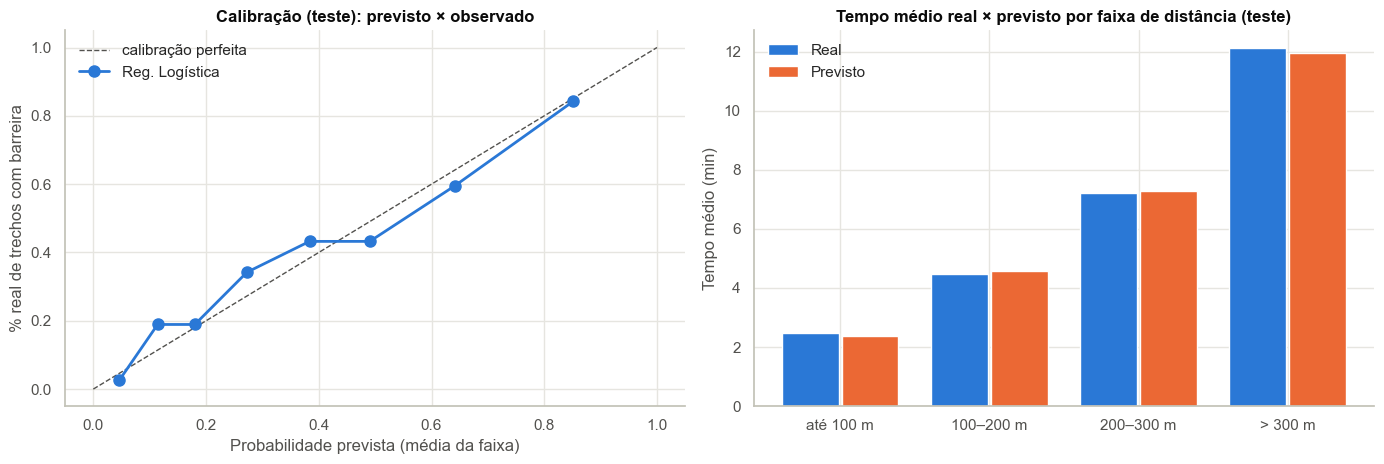

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) Calibração: a probabilidade prevista corresponde à frequência real?
frac_real, prob_media = calibration_curve(yb_test, prob_barreira, n_bins=8, strategy="quantile")
ax = axes[0]
ax.plot([0, 1], [0, 1], color=TINTA2, ls="--", lw=1, label="calibração perfeita")
ax.plot(prob_media, frac_real, marker="o", ms=8, color=AZUL, lw=2, label="Reg. Logística")
ax.set_xlabel("Probabilidade prevista (média da faixa)"); ax.set_ylabel("% real de trechos com barreira")
ax.set_title("Calibração (teste): previsto × observado"); ax.legend(frameon=False)

# (b) Tempo total previsto × real por faixa de distância
seg2 = comparacao.assign(faixa=pd.cut(comparacao["distancia_m"], [0, 100, 200, 300, 800],
                                      labels=["até 100 m", "100–200 m", "200–300 m", "> 300 m"]))
g = seg2.groupby("faixa", observed=True)[["tempo_real", "tempo_previsto"]].mean()
xpos = np.arange(len(g))
axes[1].bar(xpos - 0.2, g["tempo_real"], width=0.38, color=AZUL, label="Real")
axes[1].bar(xpos + 0.2, g["tempo_previsto"], width=0.38, color=LARANJA, label="Previsto")
axes[1].set_xticks(xpos, g.index); axes[1].set_ylabel("Tempo médio (min)")
axes[1].set_title("Tempo médio real × previsto por faixa de distância (teste)"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Leitura da comparação com a realidade da base:**
- Na tabela de 12 trechos sorteados do teste, o erro de tempo fica, na maioria, abaixo de 1 minuto. Os erros de classificação aparecem em trechos com probabilidade intermediária (0,3 a 0,6), justamente a zona de incerteza.
- **Calibração:** os pontos do gráfico acompanham a diagonal. Quando o modelo diz "60% de chance", cerca de 60% desses trechos realmente têm barreira. Isso permite mostrar a probabilidade ao usuário (ex.: "risco alto/médio/baixo"), e não só um "sim/não".
- **Tempo médio por faixa de distância:** as barras de previsto e real ficam próximas em todas as faixas, ou seja, o modelo não erra sistematicamente para mais nem para menos em nenhum tipo de trecho.

## 10. Hipóteses: o que os modelos permitem (e não permitem) afirmar

Para cada hipótese verificamos: (1) o **sinal** do coeficiente e (2) sua **estabilidade**, por *bootstrap* (reamostragem do treino 300 vezes, reajustando o modelo a cada vez) → intervalo de 95%. Se o intervalo não cruza zero, o efeito é estável **nesta base**.

> **Atenção — leitura correta deste resultado.** A base foi simulada pela própria equipe com essas relações embutidas no gerador. Encontrar o efeito esperado mostra apenas que **o modelo consegue recuperar o padrão** e que **a análise está correta tecnicamente** — **não prova** que a hipótese vale nas calçadas reais. Além disso, coeficiente de regressão indica **associação**, não causalidade. Por isso o veredito usado é "**compatível com os dados simulados**", nunca "comprovada".

In [32]:
rng_bs = np.random.default_rng(SEED)
N_BOOT = 300
coefs_lin_bs, coefs_log_bs = [], []
Xtr, ytr_t, ytr_b = X_train.reset_index(drop=True), yt_train.reset_index(drop=True), yb_train.reset_index(drop=True)
for _ in range(N_BOOT):
    i = rng_bs.integers(0, len(Xtr), len(Xtr))
    ml = Pipeline([("prep", criar_preprocessador()), ("reg", LinearRegression())]).fit(Xtr.iloc[i], ytr_t.iloc[i])
    mg = Pipeline([("prep", criar_preprocessador()), ("clf", LogisticRegression(max_iter=1000))]).fit(Xtr.iloc[i], ytr_b.iloc[i])
    coefs_lin_bs.append(ml.named_steps["reg"].coef_)
    coefs_log_bs.append(mg.named_steps["clf"].coef_[0])
coefs_lin_bs, coefs_log_bs = np.array(coefs_lin_bs), np.array(coefs_log_bs)

def ic(arr, nome):
    j = NOMES_FEATURES.index(nome)
    return np.percentile(arr[:, j], [2.5, 97.5])

linhas = []
def avalia(h, descricao, modelo, nome, sinal_esperado):
    arr = coefs_lin_bs if modelo == "Linear" else coefs_log_bs
    est = (coef_lin if modelo == "Linear" else coef_log).set_index("variável").loc[nome, "coef. padronizado"]
    lo, hi = ic(arr, nome)
    estavel = (lo > 0) if sinal_esperado > 0 else (hi < 0)
    linhas.append([h, descricao, modelo, nome, round(est, 3), f"[{lo:.3f}; {hi:.3f}]",
                   "compatível com os dados simulados" if estavel and np.sign(est) == sinal_esperado
                   else "NÃO sustentada nesta base"])

avalia("H1", "inclinação ↑ → tempo ↑", "Linear", "inclinacao_pct", +1)
avalia("H2", "com rampa → chance de barreira ↓", "Logística", "presenca_rampa", -1)
avalia("H3a", "largura ↑ → chance de barreira ↓", "Logística", "largura_calcada_m", -1)
avalia("H3b", "obstáculos ↑ → chance de barreira ↑", "Logística", "qtd_obstaculos", +1)
avalia("H4a", "pavimento ruim → tempo ↑", "Linear", "pavimento_ruim", +1)
avalia("H4b", "pavimento ruim → chance de barreira ↑", "Logística", "pavimento_ruim", +1)

hipoteses = pd.DataFrame(linhas, columns=["Hipótese", "Enunciado", "Modelo", "Variável", "Coef. (padronizado)",
                                          "IC 95% bootstrap", "Veredito nesta base"])
hipoteses

,Hipótese,Enunciado,Modelo,Variável,Coef. (padronizado),IC 95% bootstrap,Veredito nesta base
0,H1,inclinação ↑ → tempo ↑,Linear,inclinacao_pct,0.836,[0.757; 0.933],compatível com os dados simulados
1,H2,com rampa → chance de barreira ↓,Logística,presenca_rampa,-1.408,[-1.710; -1.129],compatível com os dados simulados
2,H3a,largura ↑ → chance de barreira ↓,Logística,largura_calcada_m,-0.738,[-0.929; -0.577],compatível com os dados simulados
3,H3b,obstáculos ↑ → chance de barreira ↑,Logística,qtd_obstaculos,0.407,[0.232; 0.553],compatível com os dados simulados
4,H4a,pavimento ruim → tempo ↑,Linear,pavimento_ruim,1.246,[1.101; 1.406],compatível com os dados simulados
5,H4b,pavimento ruim → chance de barreira ↑,Logística,pavimento_ruim,0.953,[0.562; 1.383],compatível com os dados simulados


**Conclusão sobre as hipóteses:** as seis verificações (H1 a H4) têm o sinal esperado e intervalos de 95% que **não cruzam zero**, ou seja, são **compatíveis com os dados simulados**.

**Isso não comprova as hipóteses.** Três motivos:
1. **Circularidade:** essas relações foram colocadas no gerador da base. O modelo apenas as reencontrou. Isso valida o **método** (o código e o pipeline funcionam e recuperam efeitos conhecidos), não o **mundo real**.
2. **Associação ≠ causa:** mesmo com dados reais, um coeficiente mostra associação. Por exemplo, calçadas largas costumam ter rampa (correlação de 0,32), e parte do "efeito da largura" pode vir de bairros mais bem cuidados.
3. **Variáveis omitidas:** no mundo real, a barreira também depende de buracos, carros estacionados, obras e mobiliário, que não estão na base.

**Como comprovar de fato:** coletar trechos reais (vistoria em campo, dados abertos de calçadas, OpenStreetMap com as tags `incline`, `width`, `kerb`, `surface` e `wheelchair`), retreinar e testar em **outro bairro**, não usado no treino.

## 11. Aplicação no RotaApta: como as previsões viram decisão

### 11.1 Recomendação de rota
Uma rota é uma sequência de quarteirões. Em cada quarteirão o usuário normalmente tem **alternativas** (ex.: seguir pela calçada da esquerda ou por uma rua paralela). O RotaApta decide, para cada quarteirão, **usando apenas as previsões dos modelos**:

1. Trechos com probabilidade de barreira **abaixo do limiar** (Seção 7.1) são "aptos"; entre os aptos, escolhe-se o de **menor tempo previsto** (Modelo 1);
2. Se nenhuma alternativa for apta, escolhe-se a de **menor probabilidade de barreira** e o trecho é sinalizado com **alerta** no app.

Comparamos com o critério de um mapa comum: **escolher sempre o trecho mais curto**. A simulação usa somente trechos do **conjunto de teste** (que os modelos nunca viram): cada rota tem 6 quarteirões, com 2 alternativas por quarteirão. Depois conferimos o resultado com os **valores rotulados na base simulada** (barreira e tempo registrados para cada trecho), que o app não conheceria. Não são medições de campo.

In [33]:
ids_teste = comparacao.index.to_numpy()

def escolher_rotaapta(alternativas):
    # Regra do RotaApta: entre os trechos aptos (p < limiar), o de menor tempo previsto;
    # se nenhum for apto, o de menor probabilidade de barreira (com alerta).
    t = comparacao.loc[alternativas]
    aptos = t[t["prob_barreira"] < LIMIAR]
    if len(aptos):
        return aptos["tempo_previsto"].idxmin(), False
    return t["prob_barreira"].idxmin(), True

def escolher_mais_curta(alternativas):
    return comparacao.loc[alternativas, "distancia_m"].idxmin()

def simular_rota(rng, n_quarteiroes=6, n_alt=2):
    quarteiroes = [rng.choice(ids_teste, n_alt, replace=False) for _ in range(n_quarteiroes)]
    esc_app = [escolher_rotaapta(q) for q in quarteiroes]
    ids_app = [e[0] for e in esc_app]
    ids_curta = [escolher_mais_curta(q) for q in quarteiroes]
    return quarteiroes, ids_app, ids_curta, sum(e[1] for e in esc_app)

def resumo_rota(ids, alertas=None):
    t = comparacao.loc[ids]
    return {"distância (m)": t["distancia_m"].sum(),
            "tempo previsto (min)": t["tempo_previsto"].sum(),
            "P(rota livre) prevista": np.prod(1 - t["prob_barreira"]),
            # abaixo: valores ROTULADOS na base simulada, só para conferência (o app não os conhece)
            "tempo registrado (min)": t["tempo_real"].sum(),
            "barreiras rotuladas": int(t["barreira_real"].sum())}

# Exemplo detalhado de UMA rota
rng_ex = np.random.default_rng(7)
quarteiroes, ids_app, ids_curta, n_alerta = simular_rota(rng_ex)
detalhe = []
for k, q in enumerate(quarteiroes, start=1):
    for tid in q:
        r = comparacao.loc[tid]
        detalhe.append({"quarteirão": k, "trecho": r["id_trecho"], "distância (m)": r["distancia_m"],
                        "tempo previsto": r["tempo_previsto"], "P(barreira)": r["prob_barreira"],
                        "mais curta escolhe": "✔" if tid in ids_curta else "",
                        "RotaApta escolhe": "✔" if tid in ids_app else "",
                        "barreira rotulada": r["barreira_real"]})
print(pd.DataFrame(detalhe).to_string(index=False))
print()
ex = pd.DataFrame({"Mais curta": resumo_rota(ids_curta), "RotaApta": resumo_rota(ids_app)}).T
ex["P(rota livre) prevista"] = ex["P(rota livre) prevista"].map("{:.1%}".format)
ex.round(2)

 quarteirão trecho  distância (m)  tempo previsto  P(barreira) mais curta escolhe RotaApta escolhe  barreira rotulada
          1  T1390        109.000           1.710        0.027                  ✔                ✔                  0
          1  T0361        166.000           3.910        0.166                                                      0
          2  T1161         94.000           4.540        0.842                  ✔                                   1
          2  T1093        279.000           9.020        0.642                                   ✔                  0
          3  T1420        183.000           6.670        0.474                                                      0
          3  T1328         75.000           3.350        0.451                  ✔                ✔                  1
          4  T1254        213.000           5.930        0.565                                                      0
          4  T1388         99.000           2.400       

,distância (m),tempo previsto (min),P(rota livre) prevista,tempo registrado (min),barreiras rotuladas
Mais curta,580.000,15.240,6.2%,14.410,2.000
RotaApta,765.000,19.720,14.0%,20.700,1.000


In [34]:
# Em escala: 1.000 rotas simuladas com trechos do conjunto de teste
rng_sim = np.random.default_rng(123)
linhas = []
for _ in range(1000):
    _, ids_app, ids_curta, n_alerta = simular_rota(rng_sim)
    a, c = resumo_rota(ids_app), resumo_rota(ids_curta)
    linhas.append({"barr_app": a["barreiras rotuladas"], "barr_curta": c["barreiras rotuladas"],
                   "tempo_app": a["tempo registrado (min)"], "tempo_curta": c["tempo registrado (min)"],
                   "dist_app": a["distância (m)"], "dist_curta": c["distância (m)"], "alertas": n_alerta})
sim = pd.DataFrame(linhas)

res_rotas = pd.DataFrame({
    "Mais curta (mapa comum)": [sim["barr_curta"].mean(), (sim["barr_curta"] == 0).mean(),
                                sim["dist_curta"].mean(), sim["tempo_curta"].mean()],
    "RotaApta": [sim["barr_app"].mean(), (sim["barr_app"] == 0).mean(),
                 sim["dist_app"].mean(), sim["tempo_app"].mean()],
}, index=["Barreiras rotuladas por rota simulada (média)", "Rotas simuladas 100% livres (rótulos)",
          "Distância média (m)", "Tempo registrado médio (min)"])
res_rotas["variação"] = [f"{res_rotas.iloc[0, 1] / res_rotas.iloc[0, 0] - 1:+.0%}",
                         f"{res_rotas.iloc[1, 1] - res_rotas.iloc[1, 0]:+.1%} p.p.".replace("%", ""),
                         f"{res_rotas.iloc[2, 1] / res_rotas.iloc[2, 0] - 1:+.0%}",
                         f"{res_rotas.iloc[3, 1] / res_rotas.iloc[3, 0] - 1:+.0%}"]
print(f"Quarteirões sem alternativa apta (alerta mostrado ao usuário): {sim['alertas'].sum() / (6 * len(sim)):.1%}")
res_rotas.round(3)

Quarteirões sem alternativa apta (alerta mostrado ao usuário): 43.1%


,Mais curta (mapa comum),RotaApta,variação
Barreiras rotuladas por rota simulada (média),2.360,1.492,-37%
Rotas simuladas 100% livres (rótulos),0.045,0.189,+14.4 p.p.
Distância média (m),860.847,"1,180.350",+37%
Tempo registrado médio (min),25.777,31.720,+23%


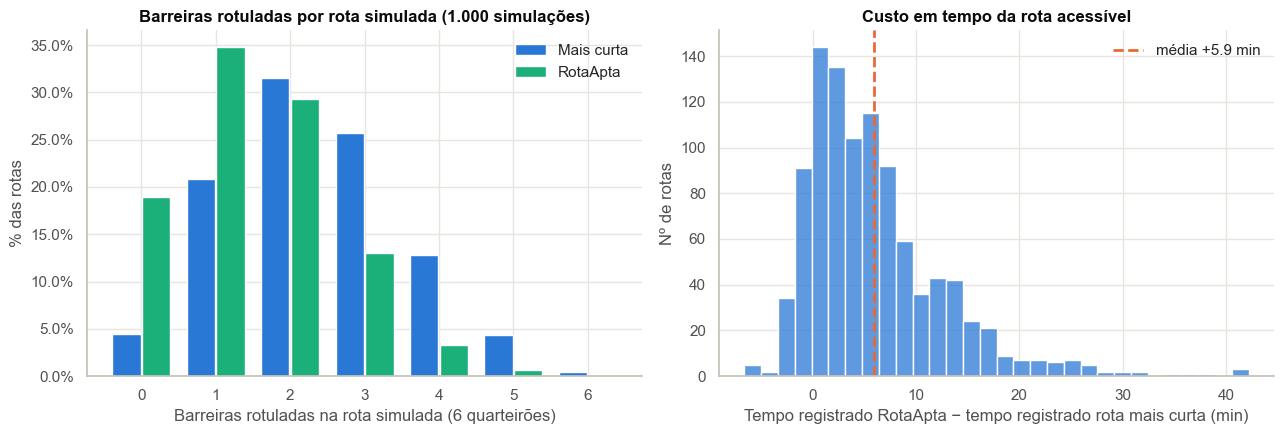

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cont = pd.DataFrame({"Mais curta": sim["barr_curta"].value_counts(normalize=True),
                     "RotaApta": sim["barr_app"].value_counts(normalize=True)}).fillna(0).sort_index()
xpos = np.arange(len(cont))
axes[0].bar(xpos - 0.2, cont["Mais curta"], width=0.38, color=AZUL, label="Mais curta")
axes[0].bar(xpos + 0.2, cont["RotaApta"], width=0.38, color=VERDE_AGUA, label="RotaApta")
axes[0].set_xticks(xpos, cont.index); axes[0].set_xlabel("Barreiras rotuladas na rota simulada (6 quarteirões)")
axes[0].set_ylabel("% das rotas"); axes[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
axes[0].set_title("Barreiras rotuladas por rota simulada (1.000 simulações)"); axes[0].legend(frameon=False)

dif = sim["tempo_app"] - sim["tempo_curta"]
sns.histplot(dif, bins=30, color=AZUL, edgecolor="white", ax=axes[1])
axes[1].axvline(dif.mean(), color=LARANJA, lw=2, ls="--", label=f"média {dif.mean():+.1f} min")
axes[1].set_xlabel("Tempo registrado RotaApta − tempo registrado rota mais curta (min)"); axes[1].set_ylabel("Nº de rotas")
axes[1].set_title("Custo em tempo da rota acessível"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

### 11.2 Priorização de reparos para a prefeitura / zeladoria
O mesmo modelo logístico permite simular "**e se**" um trecho recebesse uma intervenção (instalar rampa, remover obstáculos), comparando a probabilidade prevista antes e depois. Isso ajuda a ordenar onde cada real investido tende a remover mais barreiras.

> É uma **simulação do modelo**, não um efeito causal medido: indica prioridades para **verificação em campo**, não substitui vistoria.

In [36]:
cenario = X_test.copy()
p_atual = modelo_log.predict_proba(cenario)[:, 1]

def p_apos(mudanca):
    c = cenario.copy(); mudanca(c)
    return modelo_log.predict_proba(c)[:, 1]

intervencoes = {
    "Instalar rampa (onde não há)": lambda c: c.__setitem__("presenca_rampa", 1),
    "Remover obstáculos (zerar)": lambda c: c.__setitem__("qtd_obstaculos", 0),
    "Recapear pavimento ruim -> bom": lambda c: c.__setitem__("condicao_pavimento",
                                         c["condicao_pavimento"].replace({"ruim": "bom", " ruim": "bom"})),
}
linhas = []
for nome, f in intervencoes.items():
    p_novo = p_apos(f)
    afetados = p_novo != p_atual
    linhas.append([nome, int(afetados.sum()), p_atual[afetados].mean(), p_novo[afetados].mean(),
                   int((p_atual >= LIMIAR).sum() - (p_novo >= LIMIAR).sum())])
tab_interv = pd.DataFrame(linhas, columns=["Intervenção simulada", "trechos afetados (teste)", "P(barreira) média antes",
                                           "P(barreira) média depois", "trechos que saem do alerta"])
tab_interv

,Intervenção simulada,trechos afetados (teste),P(barreira) média antes,P(barreira) média depois,trechos que saem do alerta
0,Instalar rampa (onde não há),102,0.589,0.324,36
1,Remover obstáculos (zerar),249,0.399,0.289,39
2,Recapear pavimento ruim -> bom,72,0.447,0.290,19


In [37]:
# Ranking: trechos de maior risco e qual intervenção reduziria mais a probabilidade
rank = comparacao[["id_trecho", "distancia_m", "inclinacao_pct", "largura_calcada_m", "presenca_rampa",
                   "qtd_obstaculos", "condicao_pavimento", "prob_barreira", "barreira_real"]].copy()
for nome, f in intervencoes.items():
    rank["Δ " + nome.split(" (")[0].split(" ->")[0]] = (p_apos(f) - p_atual).round(3)
cols_delta = [c for c in rank.columns if c.startswith("Δ ")]
rank["melhor intervenção"] = rank[cols_delta].idxmin(axis=1).str.replace("Δ ", "", regex=False)
rank.loc[rank[cols_delta].min(axis=1) > -0.01, "melhor intervenção"] = "vistoria (inclinação/largura)"
top10 = rank.sort_values("prob_barreira", ascending=False).head(10)
top10

,id_trecho,distancia_m,inclinacao_pct,largura_calcada_m,presenca_rampa,qtd_obstaculos,condicao_pavimento,prob_barreira,barreira_real,Δ Instalar rampa,Δ Remover obstáculos,Δ Recapear pavimento ruim,melhor intervenção
867,T1150,317.000,12.000,0.800,0,3.000,ruim,0.991,1,-0.028,-0.013,-0.015,Instalar rampa
865,T0143,56.000,12.100,1.620,0,6.000,bom,0.977,1,-0.064,-0.101,0.000,Remover obstáculos
1167,T1442,219.000,6.300,0.600,0,4.000,ruim,0.976,1,-0.067,-0.052,-0.036,Instalar rampa
13,T0176,198.000,8.100,0.780,0,5.000,regular,0.973,1,-0.076,-0.085,0.000,Remover obstáculos
332,T0087,139.000,11.700,1.110,0,3.000,bom,0.967,1,-0.090,-0.045,0.000,Instalar rampa
812,T0224,99.000,9.600,0.740,1,6.000,bom,0.944,1,0.000,-0.210,0.000,Remover obstáculos
1101,T0117,205.000,14.600,1.380,1,1.000,ruim,0.937,1,0.000,-0.020,-0.085,Recapear pavimento ruim
620,T0909,187.000,11.900,1.180,0,1.000,bom,0.936,1,-0.155,-0.021,0.000,Instalar rampa
803,T0846,220.000,4.800,0.600,0,2.000,ruim,0.936,1,-0.155,-0.047,-0.087,Instalar rampa
194,T1164,79.000,7.100,1.010,0,4.000,bom,0.928,1,-0.169,-0.134,0.000,Instalar rampa


### 11.3 Fila de vistoria com orçamento fixo
Uma equipe de zeladoria não consegue vistoriar todos os trechos. Supondo um orçamento para vistoriar **20% dos trechos**, comparamos duas estratégias no conjunto de teste: seguir o **ranking de probabilidade** do modelo × **vistoriar ao acaso**. A conferência usa as barreiras rotuladas na base simulada.

In [38]:
k = int(np.ceil(0.20 * len(comparacao)))
fila = comparacao.sort_values("prob_barreira", ascending=False, kind="stable").head(k)
achadas = int(fila["barreira_real"].sum())
total_barreiras = int(comparacao["barreira_real"].sum())
esperado_acaso = k * comparacao["barreira_real"].mean()

print(f"Orçamento: {k} vistorias (20% dos {len(comparacao)} trechos de teste)")
print(f"Seguindo o ranking do modelo: {achadas} barreiras encontradas ({achadas / k:.1%} das vistorias)")
print(f"Vistoriando ao acaso (esperado): {esperado_acaso:.0f} barreiras ({comparacao['barreira_real'].mean():.1%})")
print(f"Cobertura: o ranking encontra {achadas / total_barreiras:.1%} de todas as {total_barreiras} barreiras do teste "
      f"com 20% do esforço")

Orçamento: 60 vistorias (20% dos 299 trechos de teste)
Seguindo o ranking do modelo: 45 barreiras encontradas (75.0% das vistorias)
Vistoriando ao acaso (esperado): 23 barreiras (38.1%)
Cobertura: o ranking encontra 39.5% de todas as 114 barreiras do teste com 20% do esforço


### Interpretação — o que as previsões permitem decidir

**Recomendação de rota (11.1).** Em 1.000 rotas simuladas com trechos do teste, comparadas com os **valores rotulados na base simulada**:
- O critério RotaApta reduziu as **barreiras rotuladas por rota simulada de 2,36 para 1,49 (−37%)**.
- As rotas **totalmente livres de barreira** subiram de **4,5% para 18,9%** (+14,4 pontos percentuais).
- O **custo** foi uma rota **23% mais demorada** (31,7 contra 25,8 min, ≈ +6 min) e 37% mais longa.
- Em **43% dos quarteirões**, nenhuma das 2 alternativas ficou abaixo do limiar. Nesses casos o app escolhe a menos arriscada **e avisa o usuário**. Isso reflete a alta proporção de barreiras desta base (38%) e mostra que **só desviar não basta**: é preciso reformar.

**Priorização de reparos (11.2).** Na simulação do modelo sobre os 299 trechos do teste:
- **Instalar rampa** nos 102 trechos sem rampa reduz a probabilidade média de barreira de **0,59 para 0,32** e tira **36 trechos** do alerta. É a intervenção de maior efeito por trecho.
- **Remover obstáculos** afeta mais trechos (249), com redução de 0,40 para 0,29, e tira **39 trechos** do alerta. É a de maior alcance e normalmente a mais barata (zeladoria, fiscalização de calçada).
- **Recapear** os 72 trechos com pavimento ruim reduz de 0,45 para 0,29 e tira **19 trechos** do alerta.
- **Fila de vistoria (11.3):** com orçamento para vistoriar 20% dos trechos (60 de 299), seguir o ranking do modelo encontra **45 barreiras (75,0% de acerto)**, contra cerca de 23 (38,1%) vistoriando ao acaso. É praticamente **o dobro de barreiras pelo mesmo esforço**, cobrindo 39,5% de todas as barreiras do teste.
- O ranking final lista os trechos de maior risco e a intervenção que mais reduziria a probabilidade em cada um. Quando nenhuma intervenção ajuda (inclinação forte ou calçada estreita, que não se resolvem com zeladoria), o trecho é encaminhado para **vistoria** e projeto de obra.

## 12. Recomendações práticas, limitações e impactos esperados

### 12.1 Recomendações para o RotaApta (fundamentadas nos resultados)
| # | Recomendação | Evidência neste notebook |
|---|---|---|
| 1 | **Usar o limiar de 0,20** (e não 0,5) para marcar trechos "em alerta". Prioridade: não deixar barreira passar. | O recall sobe de 53,5% para 89,5% e as barreiras não detectadas caem de 53 para 12 no teste (Seção 7.1). |
| 2 | **Mostrar a probabilidade como nível de risco** (baixo/médio/alto), e não só "sim/não". | O modelo está bem calibrado (Seção 9). A AUC de 0,79 indica boa ordenação do risco. |
| 3 | **Recomendar a rota pela regra "apto primeiro, mais rápido depois"**, com aviso explícito quando não houver alternativa apta. | −37% de barreiras rotuladas por rota simulada e rotas simuladas 100% livres de 4,5% para 18,9% (Seção 11.1). |
| 4 | **Mostrar o custo da rota acessível** ("+6 min, 1 barreira a menos"), para o usuário decidir com informação. | Rota RotaApta ≈ 23% mais demorada (Seção 11.1). |
| 5 | **Usar a regressão linear com interações para estimar o tempo no app**, e a versão simples para explicar os fatores ao usuário e à prefeitura. | MAE de 0,48 contra 0,64 min e R² de 0,961 contra 0,915 no teste (Seção 6.1). |
| 6 | **Entregar à zeladoria um ranking de trechos**, priorizando rampas (maior efeito por trecho) e remoção de obstáculos (maior alcance, menor custo). | Rampa: probabilidade média de 0,59 para 0,32. Obstáculos: 39 trechos saem do alerta (Seção 11.2). |
| 6b | **Montar a fila de vistorias pelo ranking de risco**, reservando uma parte das vistorias para trechos de risco baixo (para encontrar barreiras que o modelo deixa passar e gerar dados de retreino). | Com 20% de orçamento, o ranking encontra 45 barreiras (75,0%), contra cerca de 23 ao acaso (Seção 11.3). |
| 7 | **Coletar dados reais antes de lançar**: vistorias colaborativas pelos próprios usuários (sem dados pessoais) + dados abertos (OpenStreetMap/prefeitura), retreinando os modelos periodicamente. | As hipóteses são apenas "compatíveis com dados simulados" (Seção 10). |

#### O custo da recomendação 1 (limiar de 0,20)
Conjunto de teste: 299 trechos, dos quais 114 têm barreira rotulada (Seção 7.1).

| Limiar | Barreiras **sem alerta** (FN) | **Falsos alertas** (FP) | Barreiras com alerta (VP) | Total de alertas (FP + VP) | % dos trechos em alerta |
|---|---|---|---|---|---|
| 0,50 | **53** de 114 | 28 | 61 | 89 | 30% |
| 0,20 | **12** de 114 | **93** | 102 | 195 | 65% |
| Diferença | **−41 barreiras sem alerta** | **+65 falsos alertas** | +41 | +106 | +35 p.p. |

**Por que priorizar o 0,20:** para o cadeirante, uma barreira sem alerta pode significar ficar preso no meio do trajeto. Um falso alerta custa um desvio de alguns minutos. A troca é de **cerca de 1,6 falso alerta a mais para cada barreira a mais detectada** (65 ÷ 41).

**O que isso exige da equipe de vistoria:** o número de trechos marcados sobe de 89 para 195, mais que o dobro, e 93 deles (48% dos alertas) não têm barreira. Esses alertas **não devem virar, todos, vistorias imediatas**. A equipe deve usar a **fila por probabilidade** (Seção 11.3: os 20% de maior risco têm 75,0% de acerto) para escolher a ordem das vistorias. Cada vistoria que confirmar ou descartar uma barreira volta para a base e permite retreinar o modelo e reduzir os falsos alertas ao longo do tempo. No app, o alerta pode aparecer com o nível de risco (alto/médio), para o usuário saber quais alertas são mais confiáveis.

### 12.2 Limitações
- **Dados simulados:** os resultados mostram que o método funciona; **não são validação em condições reais**. As métricas reais provavelmente serão piores, porque a realidade tem mais ruído e mais fatores.
- **Linearidade:** a regressão linear simples não captura efeitos multiplicativos (resíduos em funil) nem "degraus" (a largura só pesa abaixo de 1,20 m). A versão com interações reduz, mas não elimina, esse problema.
- **Variáveis ausentes:** buracos, carros na calçada, obras temporárias, iluminação, clima, tipo de cadeira (manual ou motorizada) e condicionamento físico da pessoa não estão na base. O tempo previsto é de um **"cadeirante médio"**.
- **Barreira binária:** "tem/não tem" simplifica a realidade. Uma barreira pode ser intransponível para um usuário e só incômoda para outro.
- **Independência entre trechos:** a probabilidade da rota inteira assume trechos independentes. Na realidade, trechos da mesma rua tendem a ser parecidos (o mesmo bairro, a mesma manutenção).
- **Divisão aleatória:** nesta base simulada os trechos são independentes, então a divisão aleatória é adequada. **Com dados reais, a divisão deve ser por rua ou bairro**, para evitar que trechos vizinhos e parecidos fiquem em treino e teste ao mesmo tempo, o que inflaria as métricas.
- **Simulações "e se" não são causais:** as intervenções da Seção 11.2 indicam prioridades de vistoria, não garantem o efeito.
- **Viés de cobertura:** bairros com menos usuários reportando terão menos dados e previsões piores, justamente onde a acessibilidade costuma ser pior.

### 12.3 Impactos esperados e como medi-los
| Impacto | Indicador sugerido | Relação com os ODS |
|---|---|---|
| Menos barreiras inesperadas no trajeto | % de rotas concluídas sem barreira relatada pelo usuário, medido num piloto com linha de base antes do app. *Na simulação, a regra elevou esse índice de 4,5% para 18,9%; esse valor vem de dados simulados e **não** deve ser usado como meta real.* | ODS 10.2 — inclusão de pessoas com deficiência |
| Vistorias mais produtivas | % de vistorias que encontram barreira real (na simulação: 75,0% seguindo o ranking, contra 38,1% ao acaso, a confirmar no piloto) | ODS 11.7 — espaços públicos acessíveis |
| Planejamento confiável do tempo | Erro médio entre o tempo previsto e o tempo real do trajeto (meta: MAE < 1 min por trecho) | ODS 11.2 — transporte acessível |
| Reformas mais bem direcionadas | Nº de trechos que saem do alerta por reforma realizada; tempo entre o alerta e o reparo | ODS 11.7 — espaços públicos acessíveis |
| Autonomia do cidadão | Nº de usuários ativos e % que deixam de depender de acompanhante para trajetos conhecidos (pesquisa com usuários) | ODS 10.2 |

### 12.4 Conclusão — como a Data Science faz o RotaApta funcionar
Sem os modelos, o RotaApta seria apenas um mapa com a rota mais curta. Com eles, a plataforma passa a:
1. **Prever o tempo** de cada trecho para um cadeirante (Regressão Linear: MAE de 0,64 min, 40% menor que usar só a distância; R² de 0,915; 0,48 min com interações);
2. **Estimar o risco de barreira** de cada trecho (Regressão Logística: supera a regra "sem rampa" em F1; recall de 89,5% com o limiar escolhido);
3. **Combinar as duas previsões** para recomendar rotas com menos barreiras (−37% na simulação), mostrando ao usuário o custo em tempo;
4. **Orientar a prefeitura** sobre onde investir e vistoriar primeiro (rampas e remoção de obstáculos; uma fila de vistoria que encontra o dobro de barreiras pelo mesmo esforço).

Tudo isso foi demonstrado em **dados simulados**. O próximo passo indispensável é repetir o mesmo pipeline com **dados reais de um bairro piloto**, medindo os indicadores da tabela acima.